# Volumetric reconstruction of the Allen MERFISH mouse brain

This notebook begins the three-dimensional SpatSplat proof of concept using the Allen Brain Cell Atlas MERFISH whole-brain dataset from donor `C57BL6J-638850`.

This notebook implements the initial section-held-out volumetric proof of concept. It:

- loads metadata for all available sections;
- opens the 550-gene expression matrix in backed mode;
- verifies metadata/expression overlap;
- summarizes cell counts, section coordinates, spacing, and spatial extent;
- visualizes the sampled volume and selects a contiguous pilot range;
- constructs a section-level train, validation, and sealed test split;
- trains a leakage-free shared gene-profile autoencoder;
- initializes and fits an anisotropic 3D splat field on observed training coordinates.

The full expression matrix remains on disk. Only section-balanced profile samples needed by the current experiment are loaded into memory.

In [1]:
from pathlib import Path
import os
import random
import sys

import anndata
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from dotenv import load_dotenv

PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent:
    if (
        (PROJECT_ROOT / 'pyproject.toml').exists()
        and (PROJECT_ROOT / 'spatsplat').is_dir()
        and (PROJECT_ROOT / 'paper').is_dir()
    ):
        break
    PROJECT_ROOT = PROJECT_ROOT.parent
else:
    raise RuntimeError('Could not find the spatsplat project root')

load_dotenv(PROJECT_ROOT / '.env')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from spatsplat import (
    CountMLP,
    GeneProfileAutoencoder,
    VolumetricAmplitudeSplatField,
    composition_cosine_loss,
    create_amplitude_splat_optimizer,
    evaluate_profile_autoencoder,
    farthest_point_sample_indices,
    log_total_count_loss,
    mae_count_loss,
    train_profile_autoencoder,
)

try:
    from abc_atlas_access.abc_atlas_cache.abc_project_cache import AbcProjectCache
except ImportError as exc:
    raise ImportError(
        'abc_atlas_access is required. Install the project environment and rerun this cell.'
    ) from exc

display_sig_digits = 4

def format_scalar(value):
    if isinstance(value, (bool, np.bool_)):
        return bool(value)
    if isinstance(value, (int, np.integer)):
        return int(value)
    if isinstance(value, (float, np.floating)):
        value = float(value)
        return value if not np.isfinite(value) else float(f'{value:.{display_sig_digits}g}')
    return value

def format_for_display(value):
    if isinstance(value, dict):
        return {key: format_for_display(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return type(value)(format_for_display(item) for item in value)
    return format_scalar(value)

FIGURE_EXPORT_DIR = PROJECT_ROOT / 'figures' / 'volumetric_reconstruction-allen_merfish-mouse_brain'
FIGURE_EXPORT_DIR.mkdir(parents=True, exist_ok=True)

def save_figure(fig, name, dpi=300):
    path = FIGURE_EXPORT_DIR / f'{name}.png'
    fig.savefig(path, dpi=dpi, bbox_inches='tight', facecolor='white')
    return path

In [2]:
data_dir = os.getenv('SPATSPLAT_DATA_DIR')
if not data_dir:
    raise RuntimeError(
        'SPATSPLAT_DATA_DIR is not set; copy .env.example to .env and configure it.'
    )

download_base = Path(
    os.getenv(
        'SPATSPLAT_ABC_ATLAS_DIR',
        str(Path(data_dir) / 'raw' / 'abc_atlas'),
    )
)
dataset_directory = 'MERFISH-C57BL6J-638850'
metadata_file = 'cell_metadata'
expression_file = 'C57BL6J-638850/log2'
expected_section_count = 59
volume_sample_per_section = 2000
random_seed = 3107

print(format_for_display({
    'abc_atlas_cache': str(download_base),
    'dataset_directory': dataset_directory,
    'expression_access': 'backed',
    'figure_directory': str(FIGURE_EXPORT_DIR),
}))

{'abc_atlas_cache': '/data/spatsplat/data/raw/abc_atlas', 'dataset_directory': 'MERFISH-C57BL6J-638850', 'expression_access': 'backed', 'figure_directory': '/home/javeda/Documents/Research/spatsplat/figures/volumetric_reconstruction-allen_merfish-mouse_brain'}


## Open the complete dataset

Cell metadata are loaded into memory because they provide the registered `x`, `y`, and `z` coordinates needed to characterize the volume. The much larger expression matrix is opened with `backed='r'`, so its values are read only when a later cell requests specific rows.

In [3]:
abc_cache = AbcProjectCache.from_cache_dir(download_base)

cell_metadata = abc_cache.get_metadata_dataframe(
    directory=dataset_directory,
    file_name=metadata_file,
    dtype={'cell_label': str},
).set_index('cell_label')
cell_metadata.index = cell_metadata.index.astype(str)

expression_path = abc_cache.get_file_path(
    directory=dataset_directory,
    file_name=expression_file,
)
expression_backed = anndata.read_h5ad(expression_path, backed='r')

print(format_for_display({
    'metadata_shape': tuple(cell_metadata.shape),
    'expression_shape': tuple(expression_backed.shape),
    'expression_path': str(expression_path),
    'metadata_columns': list(cell_metadata.columns),
}))

/home/javeda/miniconda3/envs/spatsplat/lib/python3.11/site-packages/abc_atlas_access/abc_atlas_cache/cloud_cache.py:679: OutdatedManifestWarning: You are loading releases/20260415/manifest.json. A more up to date version of the dataset -- releases/20260711/manifest.json -- exists online. To see the changes between the two versions of the dataset, run
type.compare_manifests('releases/20260415/manifest.json', 'releases/20260711/manifest.json')
To load another version of the dataset, run
type.load_manifest('releases/20260711/manifest.json')
  warnings.warn(msg, OutdatedManifestWarning)


{'metadata_shape': (3938808, 11), 'expression_shape': (4334174, 550), 'expression_path': '/data/spatsplat/data/raw/abc_atlas/expression_matrices/MERFISH-C57BL6J-638850/20230830/C57BL6J-638850-log2.h5ad', 'metadata_columns': ['brain_section_label', 'cluster_alias', 'average_correlation_score', 'feature_matrix_label', 'donor_label', 'donor_genotype', 'donor_sex', 'x', 'y', 'z', 'abc_sample_id']}


## Dataset integrity and analysis population

The released expression matrix contains more rows than the coordinate metadata table. Volumetric modeling requires registered coordinates, so the initial analysis population is the intersection of expression rows and metadata rows. The checks below make that choice explicit rather than silently dropping unmatched observations.

In [4]:
def section_order_key(section_label):
    donor_prefix, suffix = str(section_label).rsplit('.', 1)
    return donor_prefix, int(suffix)

metadata_ids = pd.Index(cell_metadata.index.astype(str))
expression_ids = pd.Index(expression_backed.obs_names.astype(str))
shared_ids = metadata_ids.intersection(expression_ids, sort=False)
metadata_only_ids = metadata_ids.difference(expression_ids, sort=False)
expression_only_ids = expression_ids.difference(metadata_ids, sort=False)

metadata_section_labels = sorted(
    cell_metadata['brain_section_label'].astype(str).unique(),
    key=section_order_key,
)
expression_section_labels = sorted(
    expression_backed.obs['brain_section_label'].astype(str).unique(),
    key=section_order_key,
)
donor_labels = sorted(cell_metadata['donor_label'].astype(str).unique())

integrity_summary = {
    'metadata_rows': len(metadata_ids),
    'expression_rows': len(expression_ids),
    'shared_rows_used_for_analysis': len(shared_ids),
    'metadata_only_rows': len(metadata_only_ids),
    'expression_only_rows_without_coordinate_metadata': len(expression_only_ids),
    'metadata_ids_unique': metadata_ids.is_unique,
    'expression_ids_unique': expression_ids.is_unique,
    'donors': donor_labels,
    'metadata_sections': len(metadata_section_labels),
    'expression_sections': len(expression_section_labels),
    'section_labels_match': metadata_section_labels == expression_section_labels,
    'genes': expression_backed.n_vars,
}
print(format_for_display(integrity_summary))

assert len(metadata_section_labels) == expected_section_count
assert metadata_section_labels == expression_section_labels
assert len(metadata_only_ids) == 0
assert len(donor_labels) == 1

{'metadata_rows': 3938808, 'expression_rows': 4334174, 'shared_rows_used_for_analysis': 3938808, 'metadata_only_rows': 0, 'expression_only_rows_without_coordinate_metadata': 395366, 'metadata_ids_unique': True, 'expression_ids_unique': True, 'donors': ['C57BL6J-638850'], 'metadata_sections': 59, 'expression_sections': 59, 'section_labels_match': True, 'genes': 550}


## Per-section population and geometry

The table orders sections by their median registered `z` coordinate. Coordinate units are reported exactly as provided by the atlas metadata; no conversion to physical distance is assumed at this stage. Gaps in numeric section labels and `z` coordinates are retained because later holdout design must distinguish ordinary neighboring planes from larger acquisition gaps.

In [5]:
section_summary = (
    cell_metadata
    .groupby('brain_section_label', observed=True)
    .agg(
        metadata_cells=('brain_section_label', 'size'),
        donor_label=('donor_label', 'first'),
        median_z=('z', 'median'),
        z_min=('z', 'min'),
        z_max=('z', 'max'),
        x_min=('x', 'min'),
        x_max=('x', 'max'),
        y_min=('y', 'min'),
        y_max=('y', 'max'),
        median_correlation_score=('average_correlation_score', 'median'),
    )
    .reset_index()
)
expression_cells = (
    expression_backed.obs['brain_section_label']
    .astype(str)
    .value_counts()
    .rename('expression_cells')
)
section_summary['brain_section_label'] = section_summary['brain_section_label'].astype(str)
section_summary = section_summary.join(
    expression_cells,
    on='brain_section_label',
    validate='one_to_one',
)
section_summary['section_number'] = section_summary['brain_section_label'].map(
    lambda label: section_order_key(label)[1]
)
section_summary['x_span'] = section_summary['x_max'] - section_summary['x_min']
section_summary['y_span'] = section_summary['y_max'] - section_summary['y_min']
section_summary['metadata_fraction_of_expression'] = (
    section_summary['metadata_cells'] / section_summary['expression_cells']
)
section_summary = section_summary.sort_values(
    ['median_z', 'section_number']
).reset_index(drop=True)
section_summary['delta_z_from_previous'] = section_summary['median_z'].diff()

cells_per_section = section_summary['metadata_cells']
z_spacing = section_summary['delta_z_from_previous'].dropna()
observed_section_numbers = section_summary['section_number'].to_numpy()
unrepresented_suffixes = sorted(
    set(range(int(observed_section_numbers.min()), int(observed_section_numbers.max()) + 1))
    - set(observed_section_numbers)
)

population_summary = {
    'sections': len(section_summary),
    'metadata_matched_cells': int(cells_per_section.sum()),
    'cells_per_section_mean': cells_per_section.mean(),
    'cells_per_section_median': cells_per_section.median(),
    'cells_per_section_q25': cells_per_section.quantile(0.25),
    'cells_per_section_q75': cells_per_section.quantile(0.75),
    'cells_per_section_min': int(cells_per_section.min()),
    'cells_per_section_max': int(cells_per_section.max()),
    'z_min': section_summary['median_z'].min(),
    'z_max': section_summary['median_z'].max(),
    'adjacent_z_spacing_min': z_spacing.min(),
    'adjacent_z_spacing_median': z_spacing.median(),
    'adjacent_z_spacing_max': z_spacing.max(),
    'unrepresented_numeric_section_suffixes': unrepresented_suffixes,
}
print(format_for_display(population_summary))

spacing_frequency = (
    z_spacing.round(6)
    .value_counts()
    .sort_index()
    .rename_axis('delta_z')
    .reset_index(name='adjacent_section_pairs')
)
display(spacing_frequency.map(format_scalar))
display(section_summary.map(format_scalar))

{'sections': 59, 'metadata_matched_cells': 3938808, 'cells_per_section_mean': 66760.0, 'cells_per_section_median': 71230.0, 'cells_per_section_q25': 44520.0, 'cells_per_section_q75': 90600.0, 'cells_per_section_min': 13963, 'cells_per_section_max': 120186, 'z_min': 0.0, 'z_max': 15.0, 'adjacent_z_spacing_min': 0.2, 'adjacent_z_spacing_median': 0.2, 'adjacent_z_spacing_max': 0.8, 'unrepresented_numeric_section_suffixes': [7, 20, 21, 22, 23, 34, 41, 53, 63, 65]}


,delta_z,adjacent_section_pairs
0,0.2,45
1,0.4,11
2,0.8,2


,brain_section_label,metadata_cells,donor_label,median_z,z_min,z_max,x_min,x_max,y_min,y_max,median_correlation_score,expression_cells,section_number,x_span,y_span,metadata_fraction_of_expression,delta_z_from_previous
0,C57BL6J-638850.01,23389,C57BL6J-638850,0.0,0.0,0.0,3.3350,7.513,3.633,7.729,0.6554,26230,1,4.178,4.097,0.8917,NaN
1,C57BL6J-638850.02,25792,C57BL6J-638850,0.2,0.2,0.2,3.2580,7.737,3.603,7.363,0.6539,29300,2,4.479,3.760,0.8803,0.2
2,C57BL6J-638850.03,30546,C57BL6J-638850,0.4,0.4,0.4,2.9110,7.814,3.313,7.781,0.6529,36043,3,4.903,4.468,0.8475,0.2
3,C57BL6J-638850.04,43047,C57BL6J-638850,0.6,0.6,0.6,2.6280,8.143,3.123,7.912,0.6764,47461,4,5.515,4.789,0.9070,0.2
4,C57BL6J-638850.05,45915,C57BL6J-638850,0.8,0.8,0.8,2.2650,8.392,2.967,8.133,0.6600,51012,5,6.127,5.166,0.9001,0.2
5,C57BL6J-638850.06,46526,C57BL6J-638850,1.0,1.0,1.0,2.0570,8.708,3.101,7.958,0.6645,50899,6,6.651,4.857,0.9141,0.2
6,C57BL6J-638850.08,47009,C57BL6J-638850,1.4,1.4,1.4,1.7430,8.985,2.929,8.072,0.6693,51965,8,7.242,5.143,0.9046,0.4
7,C57BL6J-638850.09,69235,C57BL6J-638850,1.6,1.6,1.6,1.0720,9.175,2.523,8.478,0.6720,75898,9,8.103,5.955,0.9122,0.2
8,C57BL6J-638850.10,42098,C57BL6J-638850,1.8,1.8,1.8,0.9431,9.345,2.747,8.188,0.6531,50303,10,8.402,5.441,0.8369,0.2
9,C57BL6J-638850.11,47690,C57BL6J-638850,2.0,2.0,2.0,0.8115,9.294,2.641,8.340,0.6637,54973,11,8.483,5.698,0.8675,0.2


## Section-level distributions

Cell count varies substantially along the stack because the tissue cross-section changes with `z`. The coordinate-span and spacing panels identify where a future alternating-section split would encounter larger anatomical or acquisition gaps.

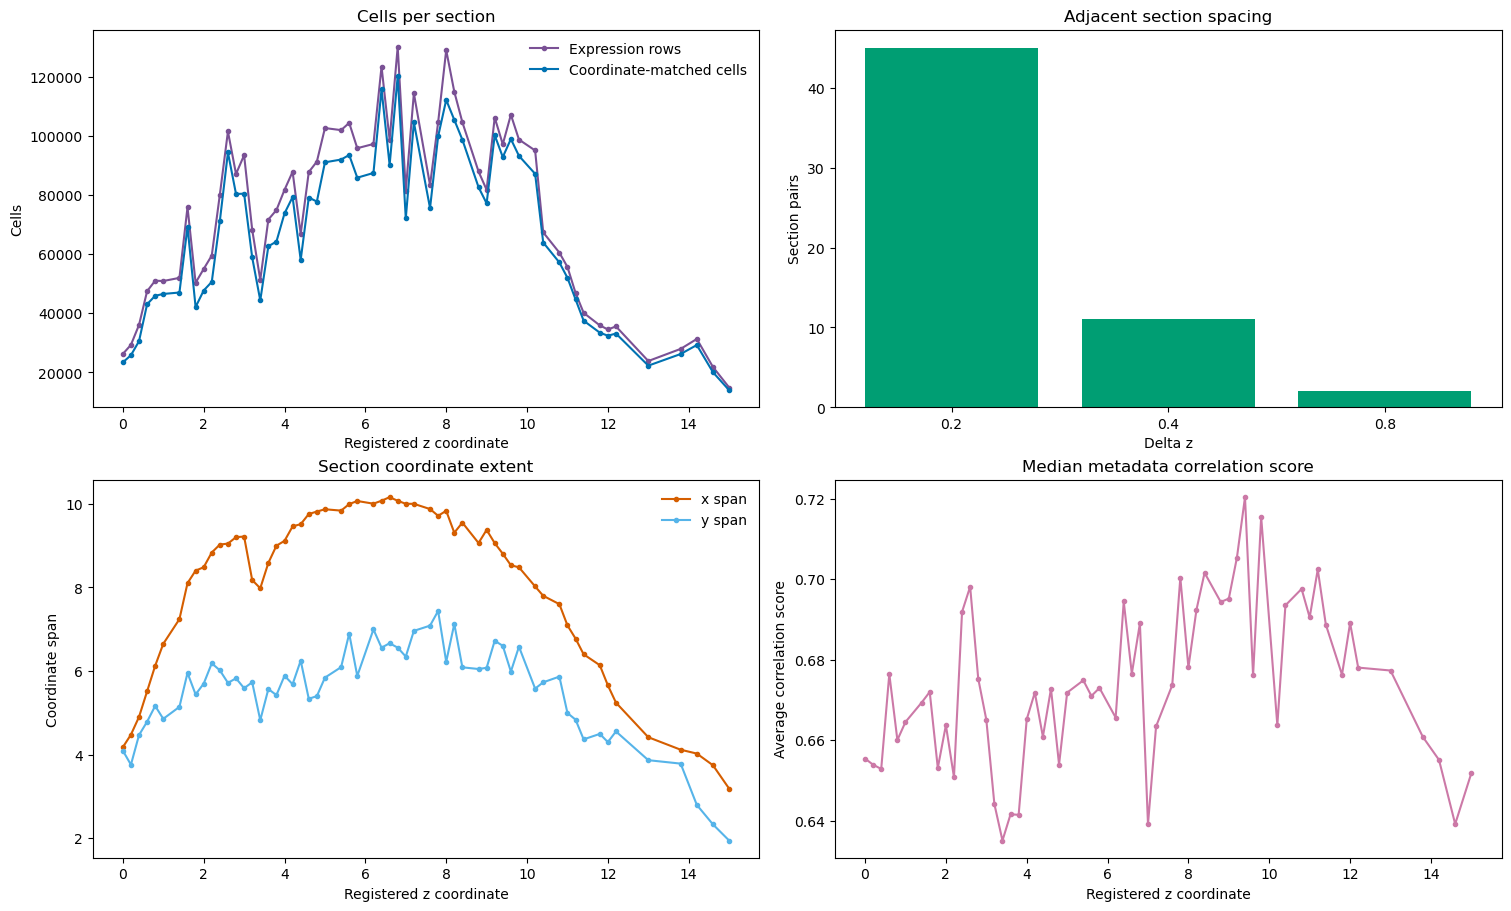

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9), constrained_layout=True)

axes[0, 0].plot(
    section_summary['median_z'],
    section_summary['expression_cells'],
    marker='o', markersize=3, linewidth=1.5,
    label='Expression rows', color='#7a5195',
)
axes[0, 0].plot(
    section_summary['median_z'],
    section_summary['metadata_cells'],
    marker='o', markersize=3, linewidth=1.5,
    label='Coordinate-matched cells', color='#0072b2',
)
axes[0, 0].set_title('Cells per section')
axes[0, 0].set_xlabel('Registered z coordinate')
axes[0, 0].set_ylabel('Cells')
axes[0, 0].legend(frameon=False)

axes[0, 1].bar(
    spacing_frequency['delta_z'].astype(str),
    spacing_frequency['adjacent_section_pairs'],
    color='#009e73',
)
axes[0, 1].set_title('Adjacent section spacing')
axes[0, 1].set_xlabel('Delta z')
axes[0, 1].set_ylabel('Section pairs')

axes[1, 0].plot(
    section_summary['median_z'], section_summary['x_span'],
    marker='o', markersize=3, label='x span', color='#d55e00',
)
axes[1, 0].plot(
    section_summary['median_z'], section_summary['y_span'],
    marker='o', markersize=3, label='y span', color='#56b4e9',
)
axes[1, 0].set_title('Section coordinate extent')
axes[1, 0].set_xlabel('Registered z coordinate')
axes[1, 0].set_ylabel('Coordinate span')
axes[1, 0].legend(frameon=False)

axes[1, 1].plot(
    section_summary['median_z'],
    section_summary['median_correlation_score'],
    marker='o', markersize=3, linewidth=1.5, color='#cc79a7',
)
axes[1, 1].set_title('Median metadata correlation score')
axes[1, 1].set_xlabel('Registered z coordinate')
axes[1, 1].set_ylabel('Average correlation score')

save_figure(fig, 'section_level_statistics')
plt.show()

## Registered volume overview

To visualize the three-dimensional sampling geometry without loading expression values, up to 2,000 coordinate-matched cells are sampled from each section. The projections reveal how tissue support changes along the sectioning axis and where the stack contains larger `z` gaps.

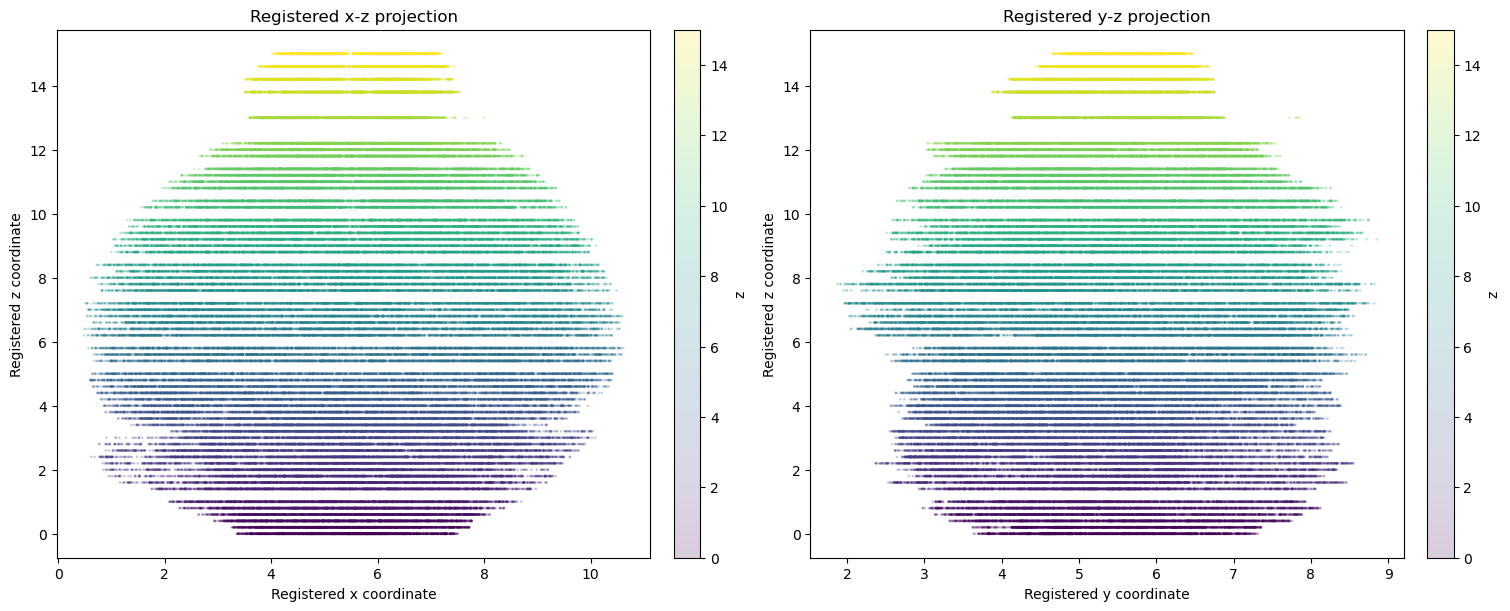

In [7]:
rng = np.random.default_rng(random_seed)
sampled_positions = []
section_groups = cell_metadata.groupby('brain_section_label', observed=True).indices
for section_label in metadata_section_labels:
    positions = np.asarray(section_groups[section_label], dtype=np.int64)
    sample_size = min(volume_sample_per_section, len(positions))
    sampled_positions.append(rng.choice(positions, size=sample_size, replace=False))
sampled_positions = np.concatenate(sampled_positions)
volume_sample = cell_metadata.iloc[sampled_positions][['x', 'y', 'z']].copy()

fig, axes = plt.subplots(1, 2, figsize=(15, 6), constrained_layout=True)
for ax, horizontal_coordinate, title in [
    (axes[0], 'x', 'Registered x-z projection'),
    (axes[1], 'y', 'Registered y-z projection'),
]:
    points = ax.scatter(
        volume_sample[horizontal_coordinate],
        volume_sample['z'],
        c=volume_sample['z'],
        s=1.0,
        alpha=0.20,
        cmap='viridis',
        rasterized=True,
    )
    ax.set_title(title)
    ax.set_xlabel(f'Registered {horizontal_coordinate} coordinate')
    ax.set_ylabel('Registered z coordinate')
    fig.colorbar(points, ax=ax, fraction=0.046, pad=0.04, label='z')

save_figure(fig, 'registered_volume_overview')
plt.show()

## Donor, cluster, and gene metadata

The dataset contains one donor and cluster aliases rather than descriptive cell-type labels in this metadata table. The initial 3D reconstruction can use the shared gene panel directly; biological domain evaluation will require joining the Allen cluster taxonomy in a later stage.

In [8]:
donor_summary = (
    cell_metadata
    .groupby('donor_label', observed=True)
    .agg(
        cells=('donor_label', 'size'),
        sections=('brain_section_label', 'nunique'),
        genotype=('donor_genotype', 'first'),
        sex=('donor_sex', 'first'),
    )
    .reset_index()
)
cluster_counts = (
    cell_metadata['cluster_alias']
    .astype(str)
    .value_counts()
    .rename_axis('cluster_alias')
    .reset_index(name='cells')
)
gene_symbols = (
    expression_backed.var['gene_symbol'].astype(str)
    if 'gene_symbol' in expression_backed.var.columns
    else pd.Series(expression_backed.var_names.astype(str))
)
gene_summary = {
    'genes': expression_backed.n_vars,
    'unique_gene_symbols': gene_symbols.nunique(),
    'duplicate_gene_symbols': int(gene_symbols.duplicated().sum()),
    'gene_examples': gene_symbols.iloc[:20].tolist(),
    'cluster_aliases': int(cell_metadata['cluster_alias'].nunique()),
    'correlation_score_median': cell_metadata['average_correlation_score'].median(),
    'correlation_score_q05': cell_metadata['average_correlation_score'].quantile(0.05),
    'correlation_score_q95': cell_metadata['average_correlation_score'].quantile(0.95),
}

print(format_for_display(gene_summary))
display(donor_summary.map(format_scalar))
display(cluster_counts.head(20).map(format_scalar))

{'genes': 550, 'unique_gene_symbols': 550, 'duplicate_gene_symbols': 0, 'gene_examples': ['Prkcq', 'Col5a1', 'Grik3', 'Igfbp2', 'Osr1', 'Syt6', 'Cntnap3', 'Lmo3', 'Ntn1', 'Otp', 'Calb1', 'Vwa5b1', 'Ptprm', 'Rxfp3', 'Cpne8', 'Igfbp6', 'Isl1', 'Shisa6', 'C230014O12Rik', 'Hspg2'], 'cluster_aliases': 5320, 'correlation_score_median': 0.6757, 'correlation_score_q05': 0.5292, 'correlation_score_q95': 0.7961}


,donor_label,cells,sections,genotype,sex
0,C57BL6J-638850,3938808,59,wt/wt,M


,cluster_alias,cells
0,5231,255305
1,5254,205305
2,5158,194580
3,5230,146086
4,14930,115768
5,14851,90047
6,14956,78580
7,4167,77806
8,14939,73366
9,232,72694


## Select an initial contiguous subvolume

The first interpolation experiment should avoid large acquisition gaps and abrupt changes in tissue footprint. Candidate runs are therefore split wherever adjacent `z` spacing differs from the modal interval. Geometry is summarized using the central 98% of x and y coordinates, which is less sensitive to isolated coordinate outliers than the full range.

The pilot window is selected without using expression values. Among eight-section windows with modal spacing, the heuristic favors stable cell counts and robust x-y spans together with high overlap between consecutive bounding rectangles. This is an engineering choice for the first model test, not a claim that anatomical dimensions should remain constant throughout the brain.

In [9]:
modal_z_spacing = float(z_spacing.round(6).mode().iloc[0])
geometry_quantiles = (
    cell_metadata
    .groupby('brain_section_label', observed=True)[['x', 'y']]
    .quantile([0.01, 0.99])
    .unstack()
)
geometry_quantiles.columns = [
    f'{coordinate}_q{int(quantile * 100):02d}'
    for coordinate, quantile in geometry_quantiles.columns
]
selection_summary = section_summary.join(
    geometry_quantiles, on='brain_section_label', validate='one_to_one'
)
selection_summary['x_span_98'] = selection_summary['x_q99'] - selection_summary['x_q01']
selection_summary['y_span_98'] = selection_summary['y_q99'] - selection_summary['y_q01']
selection_summary['x_median'] = (selection_summary['x_q01'] + selection_summary['x_q99']) / 2
selection_summary['y_median'] = (selection_summary['y_q01'] + selection_summary['y_q99']) / 2
ordinary_spacing = np.isclose(
    selection_summary['delta_z_from_previous'].fillna(modal_z_spacing),
    modal_z_spacing,
)
selection_summary['contiguous_run'] = (~ordinary_spacing).cumsum()

def consecutive_rectangle_ious(window):
    ious = []
    for row_index in range(len(window) - 1):
        first = window.iloc[row_index]
        second = window.iloc[row_index + 1]
        intersection_x = max(
            0.0, min(first['x_q99'], second['x_q99']) - max(first['x_q01'], second['x_q01'])
        )
        intersection_y = max(
            0.0, min(first['y_q99'], second['y_q99']) - max(first['y_q01'], second['y_q01'])
        )
        intersection = intersection_x * intersection_y
        first_area = first['x_span_98'] * first['y_span_98']
        second_area = second['x_span_98'] * second['y_span_98']
        ious.append(intersection / (first_area + second_area - intersection))
    return np.asarray(ious)

def summarize_candidate(window):
    rectangle_ious = consecutive_rectangle_ious(window)
    center_shift = np.hypot(
        window['x_median'].diff(), window['y_median'].diff()
    ).dropna()
    return {
        'start_section': window['brain_section_label'].iloc[0],
        'end_section': window['brain_section_label'].iloc[-1],
        'sections': len(window),
        'z_start': window['median_z'].iloc[0],
        'z_end': window['median_z'].iloc[-1],
        'minimum_cells': int(window['metadata_cells'].min()),
        'maximum_cells': int(window['metadata_cells'].max()),
        'cell_count_cv': window['metadata_cells'].std(ddof=0) / window['metadata_cells'].mean(),
        'x_span_cv': window['x_span_98'].std(ddof=0) / window['x_span_98'].mean(),
        'y_span_cv': window['y_span_98'].std(ddof=0) / window['y_span_98'].mean(),
        'median_consecutive_rectangle_iou': float(np.median(rectangle_ious)),
        'minimum_consecutive_rectangle_iou': float(np.min(rectangle_ious)),
        'maximum_center_shift': float(center_shift.max()),
    }

candidate_runs = pd.DataFrame([
    summarize_candidate(run.reset_index(drop=True))
    for _, run in selection_summary.groupby('contiguous_run', observed=True)
    if len(run) >= 3
]).sort_values(['sections', 'median_consecutive_rectangle_iou'], ascending=[False, False])
display(candidate_runs.map(format_scalar))

pilot_window_size = 8
pilot_candidates = []
pilot_candidate_labels = []
for _, run in selection_summary.groupby('contiguous_run', observed=True):
    run = run.reset_index(drop=True)
    for start_index in range(len(run) - pilot_window_size + 1):
        window = run.iloc[start_index:start_index + pilot_window_size].copy()
        summary = summarize_candidate(window)
        summary['selection_score'] = (
            summary['cell_count_cv']
            + summary['x_span_cv']
            + summary['y_span_cv']
            + 1.0 - summary['median_consecutive_rectangle_iou']
        )
        pilot_candidates.append(summary)
        pilot_candidate_labels.append(window['brain_section_label'].tolist())

pilot_candidate_table = pd.DataFrame(pilot_candidates).sort_values('selection_score')
selected_candidate_index = int(pilot_candidate_table.index[0])
pilot_section_labels = pilot_candidate_labels[selected_candidate_index]
pilot_summary = selection_summary[
    selection_summary['brain_section_label'].isin(pilot_section_labels)
].copy()
pilot_summary['pilot_role'] = 'train'
validation_section_label = pilot_section_labels[2]
test_section_label = pilot_section_labels[6]
pilot_summary.loc[
    pilot_summary['brain_section_label'] == validation_section_label, 'pilot_role'
] = 'validation holdout'
pilot_summary.loc[
    pilot_summary['brain_section_label'] == test_section_label, 'pilot_role'
] = 'test holdout'
pilot_summary['section_quality'] = 'standard'
damaged_section_label = next(
    label for label in pilot_section_labels if label.endswith('.27')
)
pilot_summary.loc[
    pilot_summary['brain_section_label'] == damaged_section_label, 'section_quality'
] = 'damaged / incomplete coverage'

print(format_for_display({
    'modal_z_spacing': modal_z_spacing,
    'selected_pilot_sections': pilot_section_labels,
    'selected_z_range': (pilot_summary['median_z'].min(), pilot_summary['median_z'].max()),
    'training_sections': pilot_summary.loc[pilot_summary['pilot_role'] == 'train', 'brain_section_label'].tolist(),
    'validation_section': validation_section_label,
    'test_section': test_section_label,
    'damaged_training_section': damaged_section_label,
}))
display(pilot_candidate_table.head(10).map(format_scalar))
display(pilot_summary[[
    'brain_section_label', 'median_z', 'metadata_cells', 'x_span_98', 'y_span_98',
    'pilot_role', 'section_quality'
]].map(format_scalar))

,start_section,end_section,sections,z_start,z_end,minimum_cells,maximum_cells,cell_count_cv,x_span_cv,y_span_cv,median_consecutive_rectangle_iou,minimum_consecutive_rectangle_iou,maximum_center_shift
1,C57BL6J-638850.08,C57BL6J-638850.30,19,1.4,5.0,42098,94385,0.23030,0.091330,0.05468,0.9051,0.6815,0.8177
3,C57BL6J-638850.35,C57BL6J-638850.40,6,6.2,7.2,72072,120186,0.17090,0.007767,0.05048,0.9143,0.8767,0.2162
5,C57BL6J-638850.47,C57BL6J-638850.52,6,8.8,9.8,77165,100214,0.09181,0.029850,0.06351,0.8773,0.8385,0.1685
0,C57BL6J-638850.01,C57BL6J-638850.06,6,0.0,1.0,23389,46526,0.26730,0.162300,0.12870,0.8413,0.7701,0.1504
4,C57BL6J-638850.42,C57BL6J-638850.46,5,7.6,8.4,75551,112169,0.12560,0.016280,0.06949,0.8874,0.8053,0.1673
6,C57BL6J-638850.56,C57BL6J-638850.59,4,10.8,11.4,37482,57175,0.15550,0.070830,0.08688,0.8551,0.8430,0.1118
2,C57BL6J-638850.31,C57BL6J-638850.33,3,5.4,5.8,85849,93525,0.03666,0.010320,0.04106,0.9239,0.8986,0.1123
7,C57BL6J-638850.60,C57BL6J-638850.62,3,11.8,12.2,32395,33435,0.01325,0.078390,0.00802,0.8594,0.8586,0.1487


{'modal_z_spacing': 0.2, 'selected_pilot_sections': ['C57BL6J-638850.19', 'C57BL6J-638850.24', 'C57BL6J-638850.25', 'C57BL6J-638850.26', 'C57BL6J-638850.27', 'C57BL6J-638850.28', 'C57BL6J-638850.29', 'C57BL6J-638850.30'], 'selected_z_range': (3.6, 5.0), 'training_sections': ['C57BL6J-638850.19', 'C57BL6J-638850.24', 'C57BL6J-638850.26', 'C57BL6J-638850.27', 'C57BL6J-638850.28', 'C57BL6J-638850.30'], 'validation_section': 'C57BL6J-638850.25', 'test_section': 'C57BL6J-638850.29', 'damaged_training_section': 'C57BL6J-638850.27'}


,start_section,end_section,sections,z_start,z_end,minimum_cells,maximum_cells,cell_count_cv,x_span_cv,y_span_cv,median_consecutive_rectangle_iou,minimum_consecutive_rectangle_iou,maximum_center_shift,selection_score
11,C57BL6J-638850.19,C57BL6J-638850.30,8,3.6,5.0,58039,91051,0.1394,0.05470,0.03213,0.9270,0.9044,0.1725,0.2992
10,C57BL6J-638850.18,C57BL6J-638850.29,8,3.4,4.8,44338,79307,0.1724,0.07574,0.04954,0.9157,0.7991,0.1267,0.3819
8,C57BL6J-638850.16,C57BL6J-638850.27,8,3.0,4.4,44338,80453,0.1747,0.07327,0.05039,0.9157,0.6815,0.8177,0.3827
7,C57BL6J-638850.15,C57BL6J-638850.26,8,2.8,4.2,44338,80453,0.1766,0.06505,0.05179,0.9059,0.6815,0.8177,0.3876
9,C57BL6J-638850.17,C57BL6J-638850.28,8,3.2,4.6,44338,79307,0.1719,0.08098,0.05285,0.9059,0.6815,0.8177,0.3999
5,C57BL6J-638850.13,C57BL6J-638850.24,8,2.4,3.8,44338,94385,0.2083,0.06026,0.04937,0.9059,0.6815,0.8177,0.4121
6,C57BL6J-638850.14,C57BL6J-638850.25,8,2.6,4.0,44338,94385,0.2082,0.06091,0.05174,0.9059,0.6815,0.8177,0.4150
2,C57BL6J-638850.10,C57BL6J-638850.17,8,1.8,3.2,42098,94385,0.2658,0.05574,0.04187,0.8958,0.8070,0.5209,0.4676
4,C57BL6J-638850.12,C57BL6J-638850.19,8,2.2,3.6,44338,94385,0.2323,0.05845,0.06327,0.8782,0.6815,0.8177,0.4758
1,C57BL6J-638850.09,C57BL6J-638850.16,8,1.6,3.0,42098,94385,0.2581,0.05806,0.04451,0.8782,0.8070,0.5209,0.4825


,brain_section_label,median_z,metadata_cells,x_span_98,y_span_98,pilot_role,section_quality
17,C57BL6J-638850.19,3.6,62653,7.817,5.226,train,standard
18,C57BL6J-638850.24,3.8,64243,8.328,5.031,train,standard
19,C57BL6J-638850.25,4.0,73779,8.414,5.438,validation holdout,standard
20,C57BL6J-638850.26,4.2,79307,8.557,5.168,train,standard
21,C57BL6J-638850.27,4.4,58039,8.845,5.330,train,damaged / incomplete coverage
22,C57BL6J-638850.28,4.6,79139,9.051,4.924,train,standard
23,C57BL6J-638850.29,4.8,77777,9.210,4.987,test holdout,standard
24,C57BL6J-638850.30,5.0,91051,9.320,5.254,train,standard


### Pilot range geometry

The highlighted interval shows the selected range in the context of the complete stack. The small multiples preserve a common x-y scale, making genuine changes in section footprint visible rather than resizing each section independently.

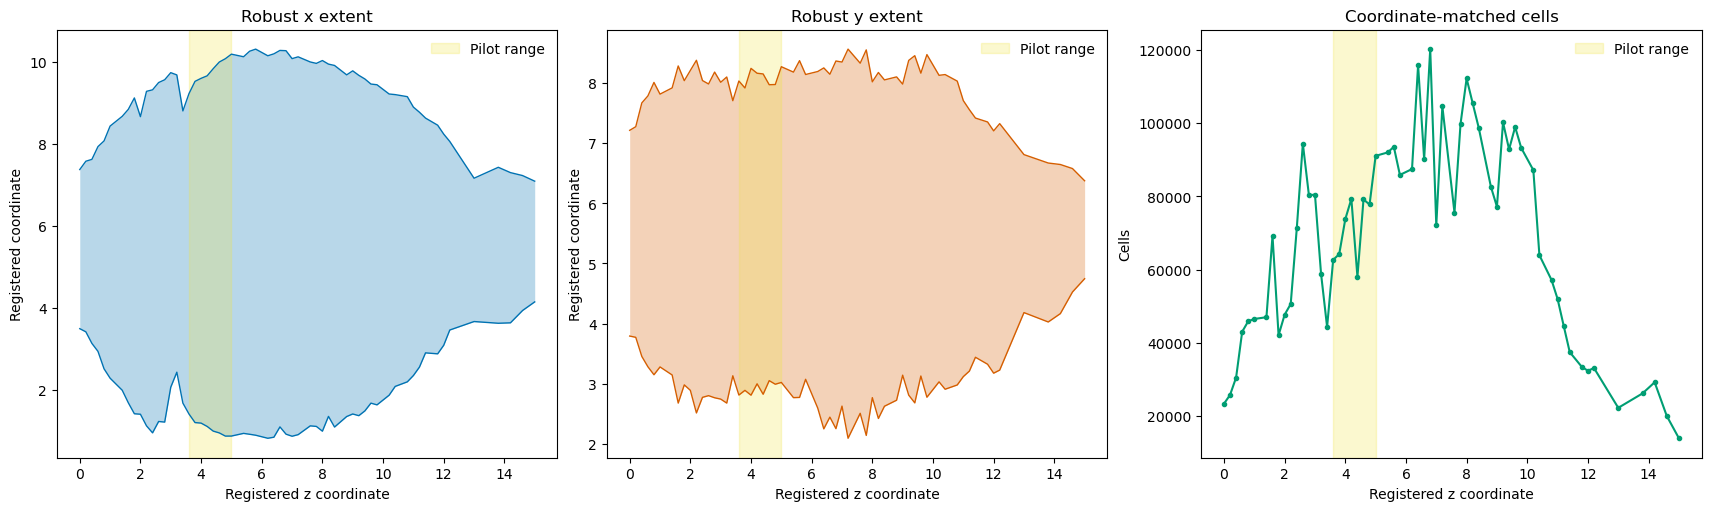

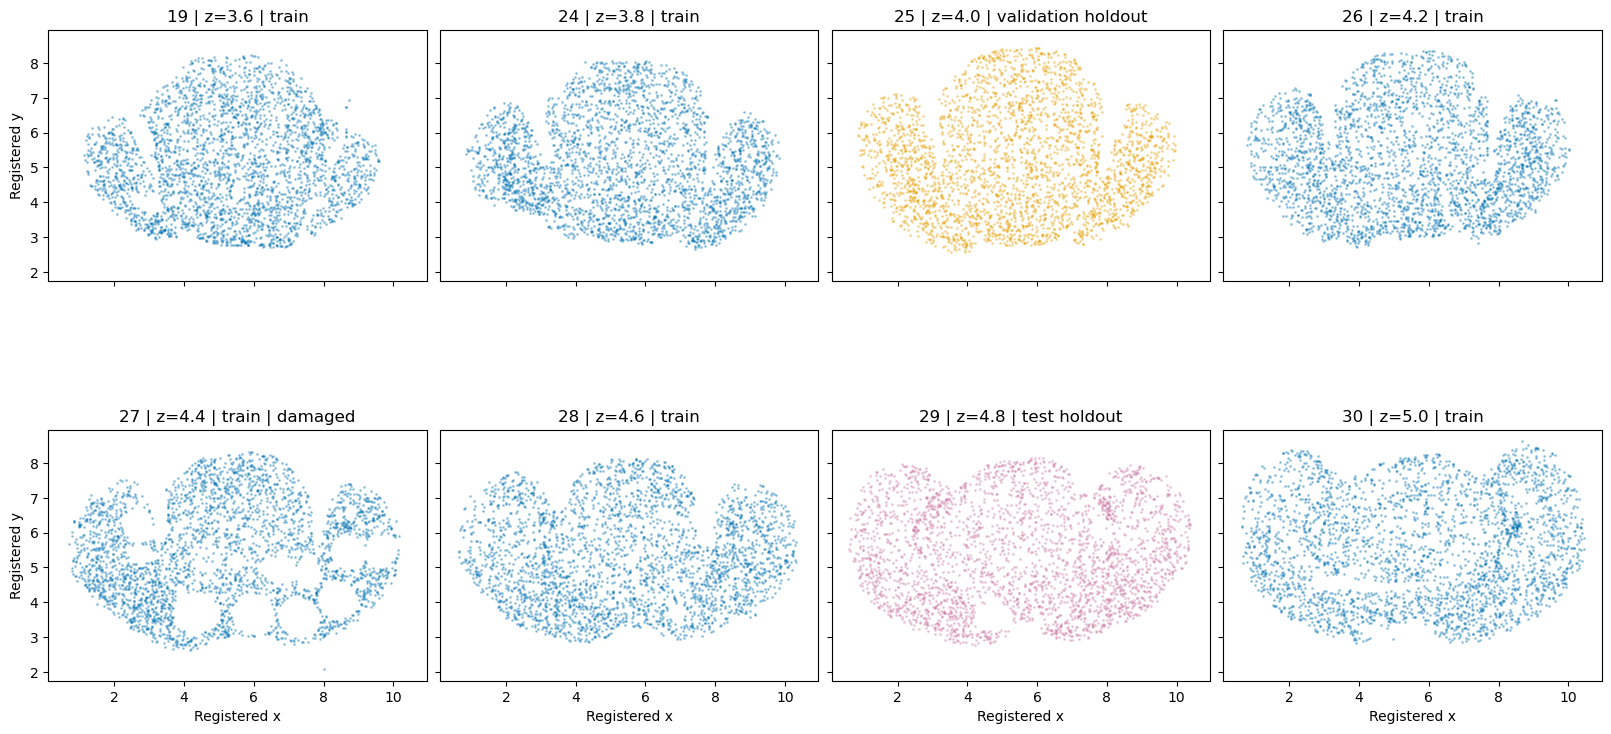

In [10]:
pilot_z_min = pilot_summary['median_z'].min()
pilot_z_max = pilot_summary['median_z'].max()
fig, axes = plt.subplots(1, 3, figsize=(17, 5), constrained_layout=True)
for ax, lower, upper, title, color in [
    (axes[0], 'x_q01', 'x_q99', 'Robust x extent', '#0072b2'),
    (axes[1], 'y_q01', 'y_q99', 'Robust y extent', '#d55e00'),
]:
    ax.fill_between(
        selection_summary['median_z'], selection_summary[lower], selection_summary[upper],
        color=color, alpha=0.28, linewidth=0,
    )
    ax.plot(selection_summary['median_z'], selection_summary[lower], color=color, linewidth=1)
    ax.plot(selection_summary['median_z'], selection_summary[upper], color=color, linewidth=1)
    ax.axvspan(pilot_z_min, pilot_z_max, color='#f0e442', alpha=0.25, label='Pilot range')
    ax.set_title(title)
    ax.set_xlabel('Registered z coordinate')
    ax.set_ylabel('Registered coordinate')
    ax.legend(frameon=False)
axes[2].plot(
    selection_summary['median_z'], selection_summary['metadata_cells'],
    marker='o', markersize=3, color='#009e73',
)
axes[2].axvspan(pilot_z_min, pilot_z_max, color='#f0e442', alpha=0.25, label='Pilot range')
axes[2].set_title('Coordinate-matched cells')
axes[2].set_xlabel('Registered z coordinate')
axes[2].set_ylabel('Cells')
axes[2].legend(frameon=False)
save_figure(fig, 'pilot_range_selection')
plt.show()

pilot_rng = np.random.default_rng(random_seed)
fig, axes = plt.subplots(2, 4, figsize=(16, 8), constrained_layout=True, sharex=True, sharey=True)
role_colors = {'train': '#0072b2', 'validation holdout': '#e69f00', 'test holdout': '#cc79a7'}
for ax, (_, section) in zip(axes.flat, pilot_summary.iterrows()):
    section_label = section['brain_section_label']
    positions = np.asarray(section_groups[section_label], dtype=np.int64)
    sample_size = min(3000, len(positions))
    sample = cell_metadata.iloc[pilot_rng.choice(positions, size=sample_size, replace=False)]
    ax.scatter(
        sample['x'], sample['y'], s=1.2, alpha=0.30,
        color=role_colors[section['pilot_role']], rasterized=True,
    )
    ax.set_title(
        f"{section_label.rsplit('.', 1)[-1]} | z={section['median_z']:.1f} | "
        f"{section['pilot_role']}"
        + (' | damaged' if section['section_quality'] != 'standard' else '')
    )
    ax.set_aspect('equal', adjustable='box')
for ax in axes[-1, :]:
    ax.set_xlabel('Registered x')
for ax in axes[:, 0]:
    ax.set_ylabel('Registered y')
save_figure(fig, 'pilot_section_footprints')
plt.show()

## Build the leakage-free expression cohort

The spatial split is defined at the section level. The autoencoder sees expression profiles only from training sections; validation expression is used for monitoring, and test expression is reserved for the final diagnostic. Equal numbers of measurements are sampled from each training section so section population does not determine the autoencoder objective.

The atlas file is the released `log2` expression matrix. Its values are therefore described as expression signal rather than raw counts. Each row is divided by its total released expression signal to obtain the compositional profile used by the autoencoder. Total signal is retained separately for the later spatial model.

In [11]:
ae_training_measurements_per_section = 10000
ae_evaluation_measurements_per_section = 20000
ae_latent_dim = 32
ae_hidden_dim = 128
ae_epochs = 150
ae_batch_size = 512
ae_learning_rate = 1e-3
ae_seed = random_seed + 1000
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

role_by_section = pilot_summary.set_index('brain_section_label')['pilot_role'].to_dict()
quality_by_section = pilot_summary.set_index('brain_section_label')['section_quality'].to_dict()
cohort_rng = np.random.default_rng(ae_seed)
sampled_cell_ids = []
for section_label in pilot_section_labels:
    available_positions = np.asarray(section_groups[section_label], dtype=np.int64)
    role = role_by_section[section_label]
    sample_cap = (
        ae_training_measurements_per_section
        if role == 'train'
        else ae_evaluation_measurements_per_section
    )
    chosen_positions = cohort_rng.choice(
        available_positions, size=min(sample_cap, len(available_positions)), replace=False
    )
    sampled_cell_ids.append(cell_metadata.index.take(chosen_positions).astype(str).to_numpy())
sampled_cell_ids = pd.Index(np.concatenate(sampled_cell_ids))

expression_positions = expression_ids.get_indexer(sampled_cell_ids)
if np.any(expression_positions < 0):
    raise RuntimeError('The sampled metadata cohort contains cells absent from the expression matrix.')
expression_positions = np.sort(expression_positions)
selected_expression = expression_backed[expression_positions].to_memory()
cohort_metadata = cell_metadata.loc[selected_expression.obs_names].copy()
cohort_metadata['brain_section_label'] = cohort_metadata['brain_section_label'].astype(str)
cohort_metadata['split'] = cohort_metadata['brain_section_label'].map(role_by_section).map({
    'train': 'train',
    'validation holdout': 'validation',
    'test holdout': 'test',
})
cohort_metadata['section_quality'] = cohort_metadata['brain_section_label'].map(quality_by_section)

expression_values = (
    selected_expression.X.toarray()
    if hasattr(selected_expression.X, 'toarray')
    else np.asarray(selected_expression.X)
).astype(np.float32, copy=False)
total_expression_signal = expression_values.sum(axis=1, keepdims=True)
positive_signal_mask = total_expression_signal[:, 0] > 0
zero_signal_measurements = int((~positive_signal_mask).sum())
if zero_signal_measurements:
    expression_values = expression_values[positive_signal_mask]
    total_expression_signal = total_expression_signal[positive_signal_mask]
    cohort_metadata = cohort_metadata.iloc[np.flatnonzero(positive_signal_mask)].copy()
expression_profiles = expression_values / np.clip(total_expression_signal, 1e-8, None)
profile_tensor = torch.from_numpy(expression_profiles)

split_indices = {
    split: torch.from_numpy(np.flatnonzero(cohort_metadata['split'].to_numpy() == split)).long()
    for split in ['train', 'validation', 'test']
}
cohort_section_summary = (
    cohort_metadata
    .assign(total_expression_signal=total_expression_signal[:, 0])
    .groupby(['brain_section_label', 'split', 'section_quality'], observed=True)
    .agg(
        sampled_measurements=('brain_section_label', 'size'),
        median_total_expression_signal=('total_expression_signal', 'median'),
        mean_total_expression_signal=('total_expression_signal', 'mean'),
    )
    .reset_index()
)

print(format_for_display({
    'device': str(device),
    'sampled_measurements': len(cohort_metadata),
    'training_measurements': len(split_indices['train']),
    'validation_measurements': len(split_indices['validation']),
    'test_measurements': len(split_indices['test']),
    'zero_signal_measurements_removed': zero_signal_measurements,
    'genes': expression_values.shape[1],
    'profile_row_sum_min': expression_profiles.sum(axis=1).min(),
    'profile_row_sum_max': expression_profiles.sum(axis=1).max(),
}))
display(cohort_section_summary.map(format_scalar))

{'device': 'cuda', 'sampled_measurements': 100000, 'training_measurements': 60000, 'validation_measurements': 20000, 'test_measurements': 20000, 'zero_signal_measurements_removed': 0, 'genes': 550, 'profile_row_sum_min': 1.0, 'profile_row_sum_max': 1.0}


,brain_section_label,split,section_quality,sampled_measurements,median_total_expression_signal,mean_total_expression_signal
0,C57BL6J-638850.19,train,standard,10000,224.2,243.5
1,C57BL6J-638850.24,train,standard,10000,191.1,203.9
2,C57BL6J-638850.25,validation,standard,20000,244.4,260.6
3,C57BL6J-638850.26,train,standard,10000,277.4,283.2
4,C57BL6J-638850.27,train,damaged / incomplete coverage,10000,234.1,243.2
5,C57BL6J-638850.28,train,standard,10000,273.4,279.0
6,C57BL6J-638850.29,test,standard,20000,261.1,271.0
7,C57BL6J-638850.30,train,standard,10000,261.0,268.8


## Preserve the registered 3D coordinate system

Coordinates are normalized once across the complete pilot range, not independently within each section. This preserves relative section dimensions and the 0.2 z spacing. Held-out coordinates are prepared for later evaluation but are not inputs to autoencoder training, because the autoencoder receives expression profiles only.

Global pilot coordinate normalization


,axis,minimum,maximum,span
0,x,0.5631,10.490,9.923
1,y,2.0750,8.626,6.551
2,z,3.6000,5.000,1.400


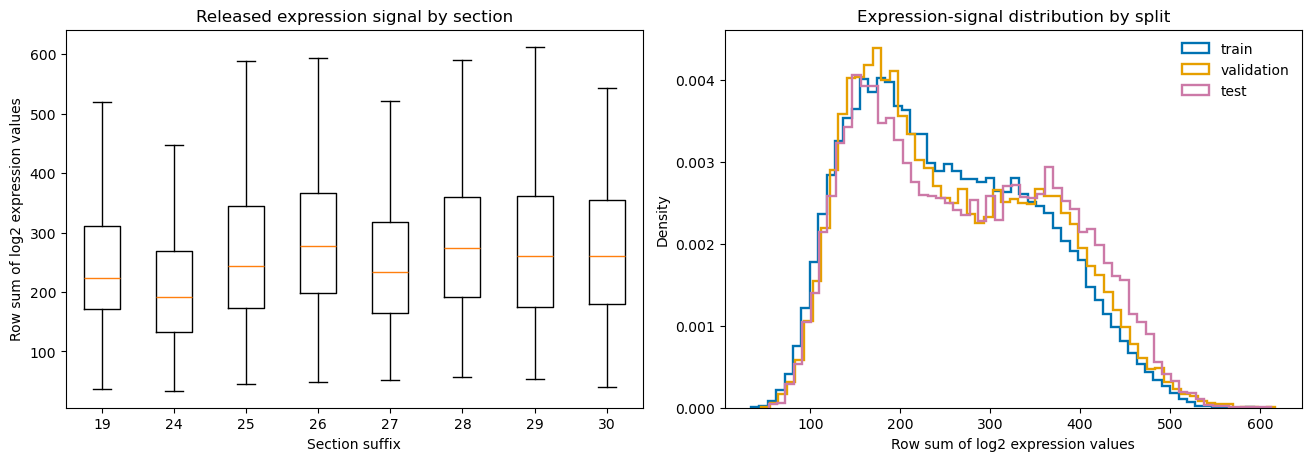

In [12]:
pilot_metadata_mask = cell_metadata['brain_section_label'].astype(str).isin(pilot_section_labels)
pilot_coordinate_support = cell_metadata.loc[pilot_metadata_mask, ['x', 'y', 'z']]
coordinate_min = pilot_coordinate_support.min(axis=0).to_numpy(dtype=np.float32)
coordinate_max = pilot_coordinate_support.max(axis=0).to_numpy(dtype=np.float32)
coordinate_span = coordinate_max - coordinate_min
if np.any(coordinate_span <= 0):
    raise RuntimeError('Pilot coordinate normalization has a non-positive axis span.')

cohort_coordinates_raw = cohort_metadata[['x', 'y', 'z']].to_numpy(dtype=np.float32)
cohort_coordinates_normalized = (cohort_coordinates_raw - coordinate_min) / coordinate_span
cohort_coordinate_tensor = torch.from_numpy(cohort_coordinates_normalized.astype(np.float32))
coordinate_normalization = pd.DataFrame({
    'axis': ['x', 'y', 'z'],
    'minimum': coordinate_min,
    'maximum': coordinate_max,
    'span': coordinate_span,
})
print('Global pilot coordinate normalization')
display(coordinate_normalization.map(format_scalar))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
section_order = pilot_summary['brain_section_label'].tolist()
signal_by_section = [
    total_expression_signal[
        cohort_metadata['brain_section_label'].to_numpy() == section_label, 0
    ]
    for section_label in section_order
]
axes[0].boxplot(signal_by_section, tick_labels=[label.rsplit('.', 1)[-1] for label in section_order], showfliers=False)
axes[0].set_title('Released expression signal by section')
axes[0].set_xlabel('Section suffix')
axes[0].set_ylabel('Row sum of log2 expression values')
split_colors = {'train': '#0072b2', 'validation': '#e69f00', 'test': '#cc79a7'}
for split, indices in split_indices.items():
    values = total_expression_signal[indices.numpy(), 0]
    axes[1].hist(
        values, bins=60, density=True, histtype='step', linewidth=1.7,
        color=split_colors[split], label=split,
    )
axes[1].set_title('Expression-signal distribution by split')
axes[1].set_xlabel('Row sum of log2 expression values')
axes[1].set_ylabel('Density')
axes[1].legend(frameon=False)
save_figure(fig, 'pilot_expression_cohort')
plt.show()

## Train the shared gene-profile autoencoder

The autoencoder compresses the 550-gene compositional profiles into a 32-dimensional latent representation. It is trained exclusively on the six training sections, including the explicitly flagged damaged section `.27`. Validation and test sections are passed only to evaluation functions. Total expression signal and spatial coordinates are not inputs to this model.

In [13]:
set_seed(ae_seed)
profile_autoencoder = GeneProfileAutoencoder(
    num_genes=profile_tensor.shape[1],
    hidden_dim=ae_hidden_dim,
    latent_dim=ae_latent_dim,
).to(device)
profile_autoencoder_optimizer = torch.optim.Adam(
    profile_autoencoder.parameters(), lr=ae_learning_rate
)

def log_ae_epoch(epoch, train_loss, validation_metrics):
    if epoch == 0 or (epoch + 1) % 10 == 0 or epoch == ae_epochs - 1:
        print(
            f'AE epoch {epoch + 1}/{ae_epochs}',
            format_for_display({
                'train_loss': train_loss,
                'validation_loss': validation_metrics['loss'],
                'validation_mae': validation_metrics['mae'],
                'validation_cosine': validation_metrics['cosine'],
            }),
        )

ae_history = train_profile_autoencoder(
    profile_autoencoder,
    profile_tensor,
    split_indices['train'],
    split_indices['validation'],
    epochs=ae_epochs,
    batch_size=ae_batch_size,
    optimizer=profile_autoencoder_optimizer,
    max_grad_norm=5.0,
    on_epoch_end=log_ae_epoch,
)

ae_split_summary = {
    split: evaluate_profile_autoencoder(
        profile_autoencoder, profile_tensor, indices, batch_size=ae_batch_size
    )
    for split, indices in split_indices.items()
}
print('Section-held-out autoencoder summary')
print(format_for_display(ae_split_summary))

AE epoch 1/150 {'train_loss': 5.899, 'validation_loss': 5.819, 'validation_mae': 0.002008, 'validation_cosine': 0.6501}
AE epoch 10/150 {'train_loss': 5.534, 'validation_loss': 5.525, 'validation_mae': 0.001518, 'validation_cosine': 0.8071}
AE epoch 20/150 {'train_loss': 5.479, 'validation_loss': 5.473, 'validation_mae': 0.001429, 'validation_cosine': 0.8346}
AE epoch 30/150 {'train_loss': 5.451, 'validation_loss': 5.447, 'validation_mae': 0.001376, 'validation_cosine': 0.8472}
AE epoch 40/150 {'train_loss': 5.434, 'validation_loss': 5.431, 'validation_mae': 0.001348, 'validation_cosine': 0.8538}
AE epoch 50/150 {'train_loss': 5.422, 'validation_loss': 5.422, 'validation_mae': 0.001331, 'validation_cosine': 0.8576}
AE epoch 60/150 {'train_loss': 5.413, 'validation_loss': 5.415, 'validation_mae': 0.00132, 'validation_cosine': 0.8602}
AE epoch 70/150 {'train_loss': 5.407, 'validation_loss': 5.409, 'validation_mae': 0.001306, 'validation_cosine': 0.8623}
AE epoch 80/150 {'train_loss': 5.4

## Autoencoder diagnostics

The split-level metrics test whether a profile encoder trained on six planes transfers to entirely unseen sections. Per-section metrics keep the damaged training section visible. Gene-wise correlation is calculated on bounded diagnostic samples and complements profile cosine by asking whether variation in individual genes is retained across measurements.

,section,split,section_quality,loss,mae,cosine,n
0,C57BL6J-638850.19,train,standard,5.377,0.001286,0.8673,10000
1,C57BL6J-638850.24,train,standard,5.313,0.001358,0.8558,10000
2,C57BL6J-638850.25,validation,standard,5.377,0.001261,0.8716,20000
3,C57BL6J-638850.26,train,standard,5.407,0.001214,0.8790,10000
4,C57BL6J-638850.27,train,damaged / incomplete coverage,5.309,0.001234,0.8767,10000
5,C57BL6J-638850.28,train,standard,5.407,0.001204,0.8801,10000
6,C57BL6J-638850.29,test,standard,5.399,0.001256,0.8717,20000
7,C57BL6J-638850.30,train,standard,5.399,0.001245,0.8721,10000


Held-out gene-wise reconstruction
{'validation': {'median_gene_correlation': 0.6053, 'mean_gene_correlation': 0.5662, 'genes_with_finite_correlation': 550}, 'test': {'median_gene_correlation': 0.5886, 'mean_gene_correlation': 0.5433, 'genes_with_finite_correlation': 550}}


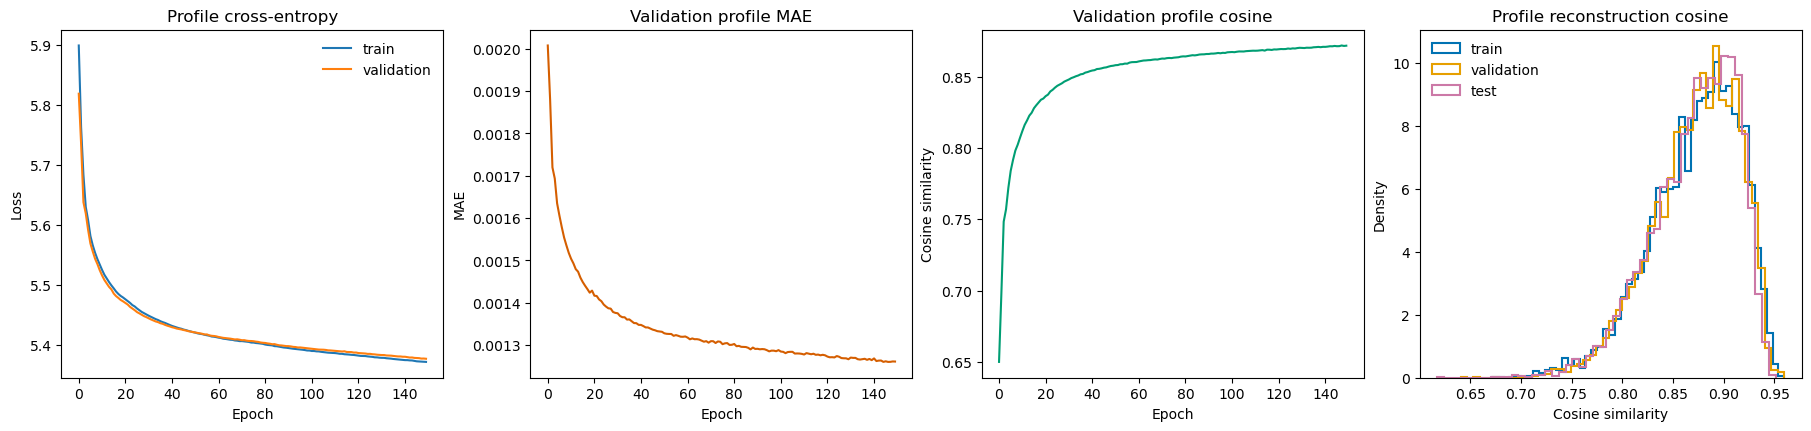

In [14]:
section_ae_rows = []
for section_label in pilot_section_labels:
    section_indices = torch.from_numpy(np.flatnonzero(
        cohort_metadata['brain_section_label'].to_numpy() == section_label
    )).long()
    metrics = evaluate_profile_autoencoder(
        profile_autoencoder, profile_tensor, section_indices, batch_size=ae_batch_size
    )
    section_ae_rows.append({
        'section': section_label,
        'split': cohort_metadata.iloc[int(section_indices[0])]['split'],
        'section_quality': quality_by_section[section_label],
        **metrics,
    })
section_ae_summary = pd.DataFrame(section_ae_rows)
display(section_ae_summary.map(format_scalar))

def reconstruct_diagnostic_sample(indices, max_measurements=5000, seed=ae_seed + 1):
    indices = indices.detach().cpu()
    if len(indices) > max_measurements:
        sample_rng = np.random.default_rng(seed)
        indices = indices[torch.from_numpy(
            np.sort(sample_rng.choice(len(indices), size=max_measurements, replace=False))
        ).long()]
    targets = profile_tensor[indices]
    reconstructed_batches = []
    profile_autoencoder.eval()
    with torch.no_grad():
        for start in range(0, len(indices), ae_batch_size):
            batch = targets[start:start + ae_batch_size].to(device)
            _, _, reconstructed = profile_autoencoder(batch)
            reconstructed_batches.append(reconstructed.cpu())
    reconstructed = torch.cat(reconstructed_batches, dim=0)
    cosine = torch.nn.functional.cosine_similarity(targets, reconstructed, dim=1).numpy()
    return targets.numpy(), reconstructed.numpy(), cosine

ae_diagnostic_samples = {
    split: reconstruct_diagnostic_sample(indices, seed=ae_seed + offset)
    for offset, (split, indices) in enumerate(split_indices.items(), start=1)
}
gene_correlation_summary = {}
for split in ['validation', 'test']:
    targets, reconstructed, _ = ae_diagnostic_samples[split]
    gene_correlations = []
    for gene_index in range(targets.shape[1]):
        target_gene = targets[:, gene_index]
        reconstructed_gene = reconstructed[:, gene_index]
        if target_gene.std() <= 1e-12 or reconstructed_gene.std() <= 1e-12:
            gene_correlations.append(np.nan)
        else:
            gene_correlations.append(np.corrcoef(target_gene, reconstructed_gene)[0, 1])
    gene_correlations = np.asarray(gene_correlations, dtype=np.float64)
    gene_correlation_summary[split] = {
        'median_gene_correlation': np.nanmedian(gene_correlations),
        'mean_gene_correlation': np.nanmean(gene_correlations),
        'genes_with_finite_correlation': int(np.isfinite(gene_correlations).sum()),
    }
print('Held-out gene-wise reconstruction')
print(format_for_display(gene_correlation_summary))

fig, axes = plt.subplots(1, 4, figsize=(18, 4.2), constrained_layout=True)
axes[0].plot(ae_history['train_loss'], label='train')
axes[0].plot(ae_history['val_loss'], label='validation')
axes[0].set_title('Profile cross-entropy')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend(frameon=False)
axes[1].plot(ae_history['val_mae'], color='#d55e00')
axes[1].set_title('Validation profile MAE')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('MAE')
axes[2].plot(ae_history['val_cosine'], color='#009e73')
axes[2].set_title('Validation profile cosine')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Cosine similarity')
for split, (_, _, cosine) in ae_diagnostic_samples.items():
    axes[3].hist(
        cosine, bins=50, density=True, histtype='step', linewidth=1.5,
        color=split_colors[split], label=split,
    )
axes[3].set_title('Profile reconstruction cosine')
axes[3].set_xlabel('Cosine similarity')
axes[3].set_ylabel('Density')
axes[3].legend(frameon=False)
save_figure(fig, 'profile_autoencoder_diagnostics')
plt.show()

## Initialize the anisotropic 3D splat field

The volumetric field uses registered `(x, y, z)` centers, an in-plane rotation, separate x-y scales, and a distinct z scale. Arbitrary 3D tilt is deliberately excluded because the registered sectioning axis has a fixed interpretation. The z scale is initialized to one ordinary section interval and constrained to remain local.

Splat x-y centers are initialized by farthest-point sampling from training coordinates. Their z coordinates are then assigned deterministic, evenly stratified positions across the open pilot volume while preserving the original ordering along z. Each initial biological program is recomputed as the autoencoder encoding of nearby training profiles at the resulting continuous 3D position, and its amplitude is the corresponding mean total expression signal. Validation and test expression are excluded from all initialization calculations.

In [15]:
volumetric_num_splats = 4096
volumetric_top_k_splats = 64
volumetric_kernel_sharpness = 1.5
volumetric_init_scale_xy = 0.04
volumetric_z_initialization = 'stratified_continuous'
normalized_section_spacing = modal_z_spacing / float(coordinate_span[2])
volumetric_init_scale_z = normalized_section_spacing
volumetric_min_scale_xy = 0.005
volumetric_max_scale_xy = 0.20
volumetric_min_scale_z = 0.5 * normalized_section_spacing
volumetric_max_scale_z = 2.0 * normalized_section_spacing
volumetric_neighbor_k = 16
volumetric_initialization_chunk_size = 256
volumetric_seed = random_seed + 2000

volumetric_coordinates = cohort_coordinate_tensor.to(device)
volumetric_targets = torch.from_numpy(expression_values).to(device)
volumetric_profiles = profile_tensor.to(device)
volumetric_split_indices = {
    split: indices.to(device) for split, indices in split_indices.items()
}
train_indices_device = volumetric_split_indices['train']
train_coordinates = volumetric_coordinates[train_indices_device]
train_profiles = volumetric_profiles[train_indices_device]
train_total_signal = volumetric_targets[train_indices_device].sum(dim=1, keepdim=True)

set_seed(volumetric_seed)
seed_local_indices = farthest_point_sample_indices(
    train_coordinates,
    volumetric_num_splats,
    candidate_limit=min(60000, len(train_coordinates)),
    random_state=volumetric_seed,
)
seed_coordinates = train_coordinates[seed_local_indices].clone()
seed_source_z = seed_coordinates[:, 2].clone()
if volumetric_z_initialization == 'stratified_continuous':
    seed_z_order = torch.argsort(seed_source_z)
    stratified_z = (
        torch.arange(
            len(seed_coordinates), dtype=seed_coordinates.dtype, device=device
        ) + 0.5
    ) / len(seed_coordinates)
    seed_coordinates[seed_z_order, 2] = stratified_z
elif volumetric_z_initialization != 'training_planes':
    raise ValueError(
        f'Unknown volumetric_z_initialization: {volumetric_z_initialization}'
    )

encoded_seed_latents = []
seed_amplitudes = []
profile_autoencoder.eval()
with torch.no_grad():
    for start in range(0, len(seed_coordinates), volumetric_initialization_chunk_size):
        seed_chunk = seed_coordinates[start:start + volumetric_initialization_chunk_size]
        distances = torch.cdist(seed_chunk, train_coordinates)
        neighbor_indices = torch.topk(
            distances,
            k=min(volumetric_neighbor_k, len(train_coordinates)),
            dim=1,
            largest=False,
            sorted=False,
        ).indices
        neighbor_profiles = train_profiles[neighbor_indices].mean(dim=1)
        neighbor_profiles = neighbor_profiles / neighbor_profiles.sum(
            dim=1, keepdim=True
        ).clamp_min(1e-8)
        encoded_seed_latents.append(profile_autoencoder.encoder(neighbor_profiles))
        seed_amplitudes.append(train_total_signal[neighbor_indices].mean(dim=1))
encoded_seed_latents = torch.cat(encoded_seed_latents, dim=0)
seed_amplitudes = torch.cat(seed_amplitudes, dim=0)

volumetric_splat_model = VolumetricAmplitudeSplatField(
    num_splats=volumetric_num_splats,
    latent_dim=ae_latent_dim,
    hidden_dim=ae_hidden_dim,
    num_genes=profile_tensor.shape[1],
    init_log_scale_xy=float(np.log(volumetric_init_scale_xy)),
    init_log_scale_z=float(np.log(volumetric_init_scale_z)),
    kernel_sharpness=volumetric_kernel_sharpness,
    top_k_splats=volumetric_top_k_splats,
    init_log_amplitude=float(train_total_signal.median().log().item()),
).to(device)
with torch.no_grad():
    volumetric_splat_model.means.copy_(seed_coordinates)
    volumetric_splat_model.latents.copy_(encoded_seed_latents)
    volumetric_splat_model.log_amplitudes.copy_(seed_amplitudes.clamp_min(1e-6).log())
    volumetric_splat_model.rotation.zero_()
    volumetric_splat_model.opacity_logits.zero_()
    volumetric_splat_model.decoder.load_state_dict(profile_autoencoder.decoder.state_dict())
for parameter in volumetric_splat_model.decoder.parameters():
    parameter.requires_grad_(False)

volumetric_initial_state = {
    'means': volumetric_splat_model.means.detach().clone(),
    'log_scales': volumetric_splat_model.log_scales.detach().clone(),
    'rotation': volumetric_splat_model.rotation.detach().clone(),
    'opacity_logits': volumetric_splat_model.opacity_logits.detach().clone(),
}
print(format_for_display({
    'device': str(device),
    'num_splats': volumetric_num_splats,
    'top_k_splats_per_query': volumetric_top_k_splats,
    'training_measurements': len(train_coordinates),
    'training_measurements_per_splat': len(train_coordinates) / volumetric_num_splats,
    'z_initialization': volumetric_z_initialization,
    'initial_z_range': (
        seed_coordinates[:, 2].min().item(), seed_coordinates[:, 2].max().item()
    ),
    'normalized_section_spacing': normalized_section_spacing,
    'initial_xy_scale': volumetric_init_scale_xy,
    'initial_z_scale': volumetric_init_scale_z,
    'z_scale_bounds': (volumetric_min_scale_z, volumetric_max_scale_z),
    'mean_seed_amplitude': seed_amplitudes.mean().item(),
    'decoder_frozen': not any(
        parameter.requires_grad for parameter in volumetric_splat_model.decoder.parameters()
    ),
}))

{'device': 'cuda', 'num_splats': 4096, 'top_k_splats_per_query': 64, 'training_measurements': 60000, 'training_measurements_per_splat': 14.65, 'z_initialization': 'stratified_continuous', 'initial_z_range': (0.0001221, 0.9999), 'normalized_section_spacing': 0.1429, 'initial_xy_scale': 0.04, 'initial_z_scale': 0.1429, 'z_scale_bounds': (0.07143, 0.2857), 'mean_seed_amplitude': 247.5, 'decoder_frozen': True}


## Train the volumetric field

Each optimization batch contains measurements from every training section. The first phase optimizes expression composition and total signal; the final quarter adds direct expression MAE while freezing geometry. Loss is evaluated only at observed training coordinates, so holes in damaged section `.27` are not converted into zero-expression targets.

The default batch size is intended for a 32 GB GPU. Increasing it further reduces the number of geometry updates per epoch and is unlikely to improve optimization simply because memory is available. Validation is evaluated every five epochs to avoid making held-out prediction the dominant computational cost. The reported field is selected using validation only: checkpoints must be within 0.002 of the best composition cosine and within 0.01 of the best log-total MAE, after which the lowest-MAE eligible checkpoint is retained. Test expression remains sealed during selection.

In [16]:
volumetric_epochs = 200
volumetric_batch_size = 8192
volumetric_evaluation_batch_size = 16384
volumetric_validation_every = 5
volumetric_log_every = 10
volumetric_checkpoint_cosine_tolerance = 0.002
volumetric_checkpoint_log_total_tolerance = 0.01
volumetric_mae_refine_fraction = 0.25
volumetric_composition_weight = 1.0
volumetric_total_signal_weight = 0.2
volumetric_mae_weight = 1.0
volumetric_means_lr = 5e-3
volumetric_log_scales_lr = 1e-3
volumetric_rotation_lr = 1e-3
volumetric_opacity_lr = 1e-3
volumetric_latents_lr = 1e-3
volumetric_amplitude_lr = 1e-3

training_indices_by_section = {
    section_label: torch.from_numpy(np.flatnonzero(
        (cohort_metadata['brain_section_label'].to_numpy() == section_label)
        & (cohort_metadata['split'].to_numpy() == 'train')
    )).long().to(device)
    for section_label in pilot_section_labels
    if role_by_section[section_label] == 'train'
}

def make_section_balanced_batches(indices_by_section, batch_size):
    section_indices = list(indices_by_section.values())
    per_section_batch_size = max(1, batch_size // len(section_indices))
    permutations = [
        indices[torch.randperm(len(indices), device=indices.device)]
        for indices in section_indices
    ]
    num_steps = max(
        int(np.ceil(len(indices) / per_section_batch_size)) for indices in permutations
    )
    for step in range(num_steps):
        start = step * per_section_batch_size
        chunks = [indices[start:start + per_section_batch_size] for indices in permutations]
        chunks = [chunk for chunk in chunks if len(chunk)]
        batch = torch.cat(chunks)
        yield batch[torch.randperm(len(batch), device=batch.device)]

def evaluate_volumetric_field(model, indices):
    was_training = model.training
    model.eval()
    totals = {'mae': 0.0, 'composition_cosine': 0.0, 'log_total_mae': 0.0}
    total_seen = 0
    with torch.no_grad():
        for start in range(0, len(indices), volumetric_evaluation_batch_size):
            batch_indices = indices[start:start + volumetric_evaluation_batch_size]
            targets = volumetric_targets[batch_indices]
            predicted_log_signal = model(volumetric_coordinates[batch_indices])
            predicted_signal = torch.exp(predicted_log_signal)
            batch_seen = len(batch_indices)
            totals['mae'] += (predicted_signal - targets).abs().mean().item() * batch_seen
            totals['composition_cosine'] += (
                1.0 - composition_cosine_loss(predicted_signal, targets).item()
            ) * batch_seen
            totals['log_total_mae'] += log_total_count_loss(
                predicted_log_signal, targets
            ).item() * batch_seen
            total_seen += batch_seen
    if was_training:
        model.train()
    return {key: value / max(total_seen, 1) for key, value in totals.items()} | {
        'n': total_seen
    }

volumetric_optimizer = create_amplitude_splat_optimizer(
    volumetric_splat_model,
    means_lr=volumetric_means_lr,
    log_scales_lr=volumetric_log_scales_lr,
    rotation_lr=volumetric_rotation_lr,
    opacity_lr=volumetric_opacity_lr,
    latents_lr=volumetric_latents_lr,
    decoder_lr=0.0,
    amplitude_lr=volumetric_amplitude_lr,
)
mae_refine_start_epoch = int(round(
    (1.0 - volumetric_mae_refine_fraction) * volumetric_epochs
))
volumetric_history = {
    'train_joint_loss': [],
    'train_composition_loss': [],
    'train_total_signal_loss': [],
    'train_mae': [],
    'validation_epoch': [],
    'validation_mae': [],
    'validation_composition_cosine': [],
    'validation_log_total_mae': [],
}
volumetric_validation_checkpoints = []

set_seed(volumetric_seed + 1)
for epoch in range(volumetric_epochs):
    volumetric_splat_model.train()
    mae_refine_active = epoch >= mae_refine_start_epoch
    geometry_lr_scale = 0.0 if mae_refine_active else 1.0
    volumetric_optimizer.param_groups[0]['lr'] = volumetric_means_lr * geometry_lr_scale
    volumetric_optimizer.param_groups[1]['lr'] = volumetric_log_scales_lr * geometry_lr_scale
    volumetric_optimizer.param_groups[2]['lr'] = volumetric_rotation_lr * geometry_lr_scale
    volumetric_optimizer.param_groups[3]['lr'] = volumetric_opacity_lr * geometry_lr_scale
    running = {'joint': 0.0, 'composition': 0.0, 'total': 0.0, 'mae': 0.0}
    total_seen = 0

    for batch_indices in make_section_balanced_batches(
        training_indices_by_section, volumetric_batch_size
    ):
        targets = volumetric_targets[batch_indices]
        predicted_log_signal = volumetric_splat_model(volumetric_coordinates[batch_indices])
        predicted_signal = torch.exp(predicted_log_signal)
        composition_loss = composition_cosine_loss(predicted_signal, targets)
        total_signal_loss = log_total_count_loss(predicted_log_signal, targets)
        mae_loss = (
            mae_count_loss(predicted_log_signal, targets)
            if mae_refine_active
            else predicted_log_signal.new_tensor(0.0)
        )
        loss = (
            volumetric_composition_weight * composition_loss
            + volumetric_total_signal_weight * total_signal_loss
            + volumetric_mae_weight * mae_loss
        )
        volumetric_optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(volumetric_splat_model.parameters(), max_norm=5.0)
        volumetric_optimizer.step()
        volumetric_splat_model.project_geometry_(
            min_scale_xy=volumetric_min_scale_xy,
            max_scale_xy=volumetric_max_scale_xy,
            min_scale_z=volumetric_min_scale_z,
            max_scale_z=volumetric_max_scale_z,
        )
        batch_seen = len(batch_indices)
        running['joint'] += loss.item() * batch_seen
        running['composition'] += composition_loss.item() * batch_seen
        running['total'] += total_signal_loss.item() * batch_seen
        running['mae'] += mae_loss.item() * batch_seen
        total_seen += batch_seen

    epoch_metrics = {key: value / total_seen for key, value in running.items()}
    volumetric_history['train_joint_loss'].append(epoch_metrics['joint'])
    volumetric_history['train_composition_loss'].append(epoch_metrics['composition'])
    volumetric_history['train_total_signal_loss'].append(epoch_metrics['total'])
    volumetric_history['train_mae'].append(epoch_metrics['mae'])
    evaluate_validation = (
        epoch == 0
        or (epoch + 1) % volumetric_validation_every == 0
        or epoch == mae_refine_start_epoch
        or epoch == volumetric_epochs - 1
    )
    validation_metrics = None
    if evaluate_validation:
        validation_metrics = evaluate_volumetric_field(
            volumetric_splat_model, volumetric_split_indices['validation']
        )
        volumetric_history['validation_epoch'].append(epoch + 1)
        volumetric_history['validation_mae'].append(validation_metrics['mae'])
        volumetric_history['validation_composition_cosine'].append(
            validation_metrics['composition_cosine']
        )
        volumetric_history['validation_log_total_mae'].append(
            validation_metrics['log_total_mae']
        )
        volumetric_validation_checkpoints.append({
            'epoch': epoch + 1,
            'metrics': validation_metrics.copy(),
            'state_dict': {
                key: value.detach().cpu().clone()
                for key, value in volumetric_splat_model.state_dict().items()
            },
        })
    if (
        epoch == 0
        or (epoch + 1) % volumetric_log_every == 0
        or epoch == volumetric_epochs - 1
    ):
        print(
            f'3D splat epoch {epoch + 1}/{volumetric_epochs}',
            'mae_refine' if mae_refine_active else 'composition',
            format_for_display({'train': epoch_metrics, 'validation': validation_metrics}),
        )

if not volumetric_validation_checkpoints:
    raise RuntimeError('Volumetric training produced no validation checkpoints.')
best_validation_cosine = max(
    checkpoint['metrics']['composition_cosine']
    for checkpoint in volumetric_validation_checkpoints
)
best_validation_log_total_mae = min(
    checkpoint['metrics']['log_total_mae']
    for checkpoint in volumetric_validation_checkpoints
)
eligible_validation_checkpoints = [
    checkpoint for checkpoint in volumetric_validation_checkpoints
    if checkpoint['metrics']['composition_cosine']
    >= best_validation_cosine - volumetric_checkpoint_cosine_tolerance
    and checkpoint['metrics']['log_total_mae']
    <= best_validation_log_total_mae + volumetric_checkpoint_log_total_tolerance
]
if not eligible_validation_checkpoints:
    raise RuntimeError(
        'No validation checkpoint satisfies the configured composition and total-signal tolerances.'
    )
selected_volumetric_checkpoint = min(
    eligible_validation_checkpoints,
    key=lambda checkpoint: (
        checkpoint['metrics']['mae'],
        -checkpoint['metrics']['composition_cosine'],
        checkpoint['metrics']['log_total_mae'],
        checkpoint['epoch'],
    ),
)
selected_volumetric_epoch = selected_volumetric_checkpoint['epoch']
volumetric_splat_model.load_state_dict(selected_volumetric_checkpoint['state_dict'])
volumetric_splat_model.to(device).eval()
validation_selected_log_scales = (
    volumetric_splat_model.log_scales.detach().clone()
)
selected_checkpoint_summary = {
    'selected_epoch': selected_volumetric_epoch,
    'eligible_checkpoints': len(eligible_validation_checkpoints),
    'evaluated_checkpoints': len(volumetric_validation_checkpoints),
    'best_validation_cosine': best_validation_cosine,
    'best_validation_log_total_mae': best_validation_log_total_mae,
    'cosine_tolerance': volumetric_checkpoint_cosine_tolerance,
    'log_total_mae_tolerance': volumetric_checkpoint_log_total_tolerance,
    'selected_validation_metrics': selected_volumetric_checkpoint['metrics'],
}
for checkpoint in volumetric_validation_checkpoints:
    checkpoint.pop('state_dict')
print('Selected volumetric validation checkpoint')
print(format_for_display(selected_checkpoint_summary))

volumetric_train_metrics = evaluate_volumetric_field(
    volumetric_splat_model, volumetric_split_indices['train']
)
volumetric_validation_metrics = evaluate_volumetric_field(
    volumetric_splat_model, volumetric_split_indices['validation']
)
volumetric_test_metrics = None
print('Volumetric field summary')
print(format_for_display({
    'train': volumetric_train_metrics,
    'validation': volumetric_validation_metrics,
    'test': volumetric_test_metrics,
    'test_status': 'sealed until the final frozen evaluation section',
}))

3D splat epoch 1/200 composition {'train': {'joint': 0.3288, 'composition': 0.2687, 'total': 0.3006, 'mae': 0.0}, 'validation': {'mae': 0.4688, 'composition_cosine': 0.7062, 'log_total_mae': 0.3392, 'n': 20000}}
3D splat epoch 10/200 composition {'train': {'joint': 0.3142, 'composition': 0.257, 'total': 0.2861, 'mae': 0.0}, 'validation': {'mae': 0.4655, 'composition_cosine': 0.7074, 'log_total_mae': 0.3408, 'n': 20000}}
3D splat epoch 20/200 composition {'train': {'joint': 0.31, 'composition': 0.2537, 'total': 0.2818, 'mae': 0.0}, 'validation': {'mae': 0.4646, 'composition_cosine': 0.7071, 'log_total_mae': 0.3418, 'n': 20000}}
3D splat epoch 30/200 composition {'train': {'joint': 0.3073, 'composition': 0.2515, 'total': 0.2788, 'mae': 0.0}, 'validation': {'mae': 0.4645, 'composition_cosine': 0.7062, 'log_total_mae': 0.3421, 'n': 20000}}
3D splat epoch 40/200 composition {'train': {'joint': 0.3051, 'composition': 0.2498, 'total': 0.2764, 'mae': 0.0}, 'validation': {'mae': 0.4637, 'compos

## Volumetric field diagnostics

The projections below show learned splat centers against the training coordinates. Learned z scales are reported in units of ordinary section intervals, making it clear whether splats remain local or repeatedly hit the imposed bounds. Test expression remains sealed by default until the validation-selected field configuration is frozen.

{'active_splats': 3319, 'active_splat_fraction': 0.8103, 'median_xy_scale': 0.03487, 'median_z_scale': 0.1287, 'median_z_scale_in_section_intervals': 0.9006, 'z_scales_at_minimum_fraction': 0.0, 'z_scales_at_maximum_fraction': 0.0}


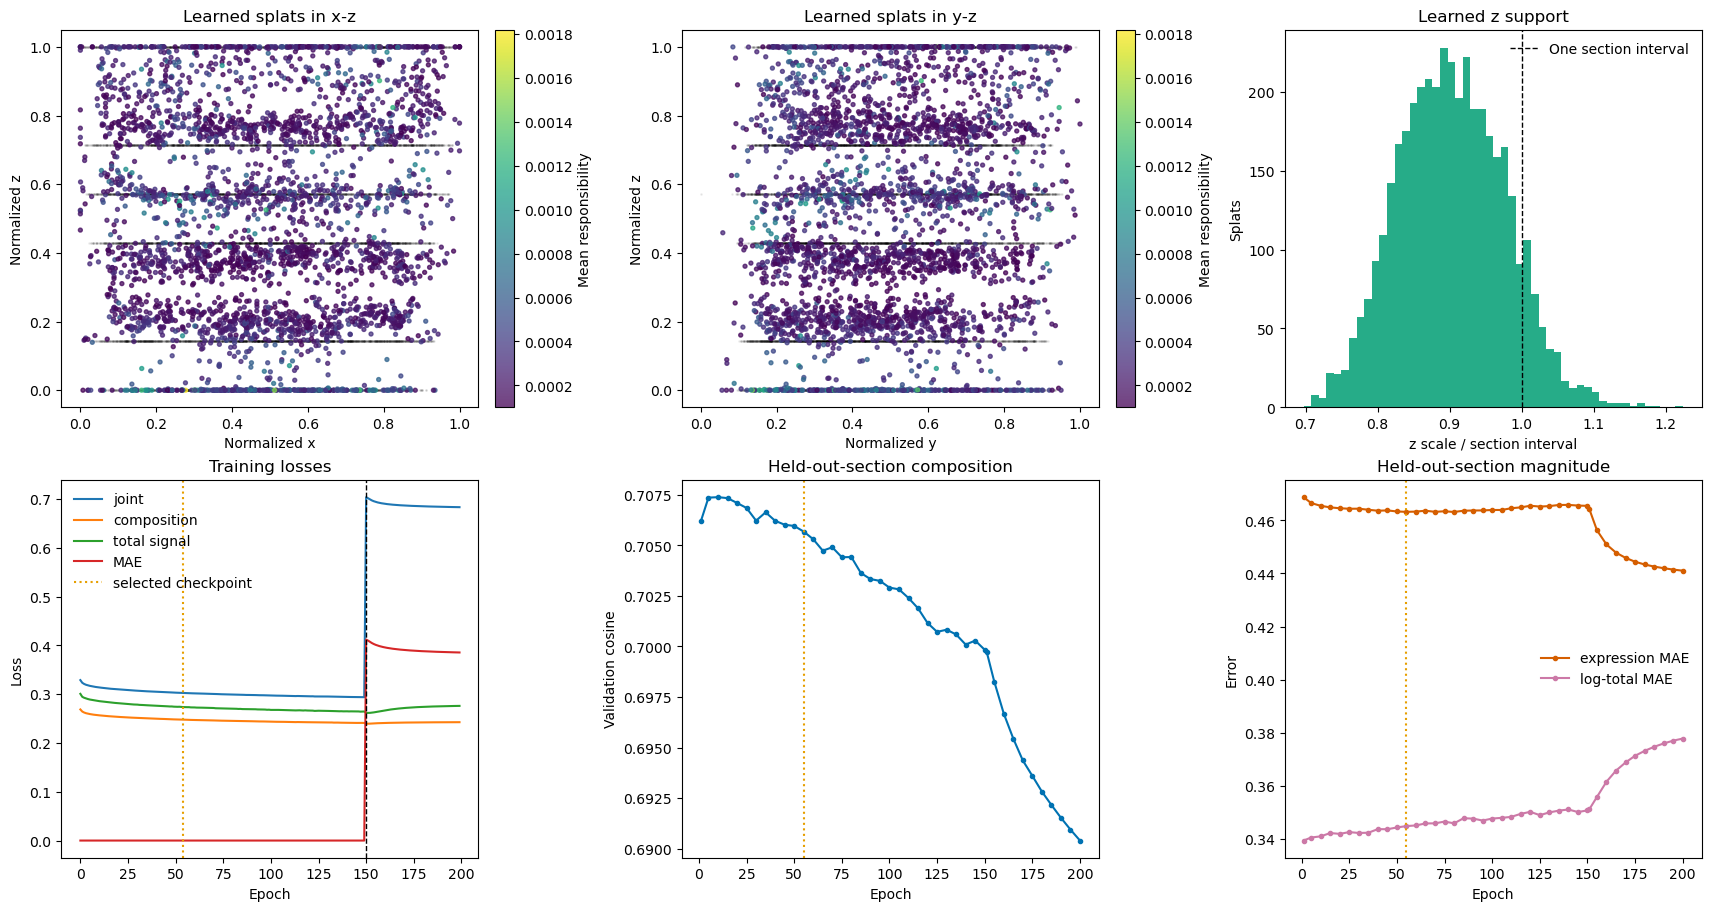

In [17]:
volumetric_splat_model.eval()
with torch.no_grad():
    learned_means = volumetric_splat_model.means.detach().cpu().numpy()
    learned_scales = volumetric_splat_model.log_scales.exp().detach().cpu().numpy()
    diagnostic_count = min(8192, len(train_indices_device))
    diagnostic_indices = train_indices_device[torch.randperm(
        len(train_indices_device), device=device
    )[:diagnostic_count]]
    diagnostic_weights = volumetric_splat_model.compute_weights(
        volumetric_coordinates[diagnostic_indices]
    )
    mean_splat_usage = diagnostic_weights.mean(dim=0).cpu().numpy()
active_splat_mask = mean_splat_usage > 1e-4
z_scales_in_section_intervals = learned_scales[:, 2] / normalized_section_spacing
print(format_for_display({
    'active_splats': int(active_splat_mask.sum()),
    'active_splat_fraction': active_splat_mask.mean(),
    'median_xy_scale': np.median(learned_scales[:, :2]),
    'median_z_scale': np.median(learned_scales[:, 2]),
    'median_z_scale_in_section_intervals': np.median(z_scales_in_section_intervals),
    'z_scales_at_minimum_fraction': np.mean(
        learned_scales[:, 2] <= volumetric_min_scale_z * 1.001
    ),
    'z_scales_at_maximum_fraction': np.mean(
        learned_scales[:, 2] >= volumetric_max_scale_z * 0.999
    ),
}))

plot_rng = np.random.default_rng(volumetric_seed + 2)
training_plot_indices = split_indices['train'].numpy()
training_plot_indices = plot_rng.choice(
    training_plot_indices, size=min(12000, len(training_plot_indices)), replace=False
)
training_plot_coordinates = cohort_coordinates_normalized[training_plot_indices]

fig, axes = plt.subplots(2, 3, figsize=(17, 9), constrained_layout=True)
for ax, horizontal_axis, title in [
    (axes[0, 0], 0, 'Learned splats in x-z'),
    (axes[0, 1], 1, 'Learned splats in y-z'),
]:
    ax.scatter(
        training_plot_coordinates[:, horizontal_axis],
        training_plot_coordinates[:, 2],
        s=1, alpha=0.06, color='black', rasterized=True,
    )
    points = ax.scatter(
        learned_means[active_splat_mask, horizontal_axis],
        learned_means[active_splat_mask, 2],
        s=8, c=mean_splat_usage[active_splat_mask], cmap='viridis', alpha=0.75,
    )
    ax.set_title(title)
    ax.set_xlabel('Normalized x' if horizontal_axis == 0 else 'Normalized y')
    ax.set_ylabel('Normalized z')
    fig.colorbar(points, ax=ax, fraction=0.046, pad=0.04, label='Mean responsibility')
axes[0, 2].hist(z_scales_in_section_intervals, bins=50, color='#009e73', alpha=0.85)
axes[0, 2].axvline(1.0, color='black', linestyle='--', linewidth=1, label='One section interval')
axes[0, 2].set_title('Learned z support')
axes[0, 2].set_xlabel('z scale / section interval')
axes[0, 2].set_ylabel('Splats')
axes[0, 2].legend(frameon=False)
axes[1, 0].plot(volumetric_history['train_joint_loss'], label='joint')
axes[1, 0].plot(volumetric_history['train_composition_loss'], label='composition')
axes[1, 0].plot(volumetric_history['train_total_signal_loss'], label='total signal')
axes[1, 0].plot(volumetric_history['train_mae'], label='MAE')
axes[1, 0].axvline(mae_refine_start_epoch, color='black', linestyle='--', linewidth=1)
axes[1, 0].axvline(
    selected_volumetric_epoch - 1, color='#e69f00', linestyle=':',
    linewidth=1.5, label='selected checkpoint',
)
axes[1, 0].set_title('Training losses')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Loss')
axes[1, 0].legend(frameon=False)
axes[1, 1].plot(
    volumetric_history['validation_epoch'],
    volumetric_history['validation_composition_cosine'],
    marker='o', markersize=3, color='#0072b2',
)
axes[1, 1].axvline(
    selected_volumetric_epoch, color='#e69f00', linestyle=':', linewidth=1.5
)
axes[1, 1].set_title('Held-out-section composition')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Validation cosine')
axes[1, 2].plot(
    volumetric_history['validation_epoch'],
    volumetric_history['validation_mae'],
    marker='o', markersize=3, color='#d55e00', label='expression MAE',
)
axes[1, 2].plot(
    volumetric_history['validation_epoch'],
    volumetric_history['validation_log_total_mae'],
    marker='o', markersize=3, color='#cc79a7', label='log-total MAE',
)
axes[1, 2].axvline(
    selected_volumetric_epoch, color='#e69f00', linestyle=':', linewidth=1.5
)
axes[1, 2].set_title('Held-out-section magnitude')
axes[1, 2].set_xlabel('Epoch')
axes[1, 2].set_ylabel('Error')
axes[1, 2].legend(frameon=False)
save_figure(fig, 'volumetric_splat_training')
plt.show()

## Learned z placement relative to section planes

The current initialization distributes z coordinates evenly across the open pilot volume while retaining training-derived x-y support. The diagnostic below tests whether optimization preserves that coverage or drives centers back toward observed training planes and the global boundaries. Distances are expressed in units of the modal section interval. A center within 0.05 intervals of a training plane is reported as plane-locked, while a center at least 0.25 intervals from every training plane is reported as substantially between planes. These thresholds describe center placement only; plane-centered splats can still interpolate through overlapping z kernels.

Splat z-placement summary
{'training_z_planes': 6, 'initial_plane_locked_fraction': 0.07153, 'learned_plane_locked_fraction': 0.198, 'learned_substantially_between_planes_fraction': 0.5776, 'learned_nearest_plane_distance_median_intervals': 0.3192, 'learned_nearest_plane_distance_q90_intervals': 0.7584, 'absolute_z_displacement_median_intervals': 0.379, 'absolute_z_displacement_q90_intervals': 0.8904, 'initial_global_boundary_fraction': 0.0, 'learned_global_boundary_fraction': 0.115}


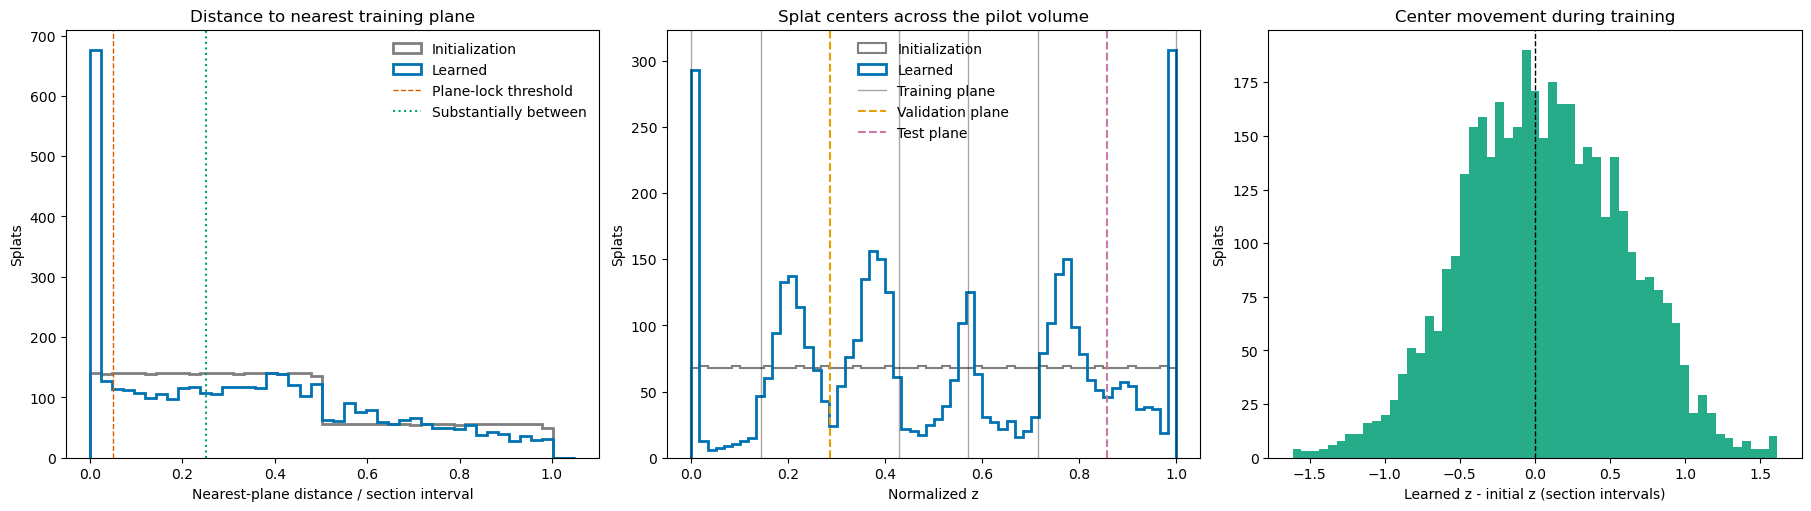

In [18]:
training_z_planes = np.unique(train_coordinates[:, 2].detach().cpu().numpy())
validation_z_planes = np.unique(
    cohort_coordinates_normalized[split_indices['validation'].numpy(), 2]
)
test_z_planes = np.unique(
    cohort_coordinates_normalized[split_indices['test'].numpy(), 2]
)
initial_splat_z = volumetric_initial_state['means'][:, 2].detach().cpu().numpy()
learned_splat_z = learned_means[:, 2]

def nearest_plane_distance_in_intervals(z_coordinates, planes):
    distances = np.abs(z_coordinates[:, None] - planes[None, :])
    return distances.min(axis=1) / normalized_section_spacing

initial_nearest_plane_distance = nearest_plane_distance_in_intervals(
    initial_splat_z, training_z_planes
)
learned_nearest_plane_distance = nearest_plane_distance_in_intervals(
    learned_splat_z, training_z_planes
)
z_displacement_in_intervals = (
    learned_splat_z - initial_splat_z
) / normalized_section_spacing
plane_lock_threshold = 0.05
substantial_between_plane_threshold = 0.25
boundary_tolerance = 1e-4

z_placement_summary = {
    'training_z_planes': len(training_z_planes),
    'initial_plane_locked_fraction': np.mean(
        initial_nearest_plane_distance <= plane_lock_threshold
    ),
    'learned_plane_locked_fraction': np.mean(
        learned_nearest_plane_distance <= plane_lock_threshold
    ),
    'learned_substantially_between_planes_fraction': np.mean(
        learned_nearest_plane_distance >= substantial_between_plane_threshold
    ),
    'learned_nearest_plane_distance_median_intervals': np.median(
        learned_nearest_plane_distance
    ),
    'learned_nearest_plane_distance_q90_intervals': np.quantile(
        learned_nearest_plane_distance, 0.90
    ),
    'absolute_z_displacement_median_intervals': np.median(
        np.abs(z_displacement_in_intervals)
    ),
    'absolute_z_displacement_q90_intervals': np.quantile(
        np.abs(z_displacement_in_intervals), 0.90
    ),
    'initial_global_boundary_fraction': np.mean(
        (initial_splat_z <= boundary_tolerance)
        | (initial_splat_z >= 1.0 - boundary_tolerance)
    ),
    'learned_global_boundary_fraction': np.mean(
        (learned_splat_z <= boundary_tolerance)
        | (learned_splat_z >= 1.0 - boundary_tolerance)
    ),
}
print('Splat z-placement summary')
print(format_for_display(z_placement_summary))

distance_upper = max(1.05, float(np.quantile(learned_nearest_plane_distance, 0.995)))
distance_bins = np.linspace(0.0, distance_upper, 45)
displacement_limit = max(
    0.5, float(np.quantile(np.abs(z_displacement_in_intervals), 0.995))
)
fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)
axes[0].hist(
    initial_nearest_plane_distance, bins=distance_bins, histtype='step',
    linewidth=2, color='#7f7f7f', label='Initialization',
)
axes[0].hist(
    learned_nearest_plane_distance, bins=distance_bins, histtype='step',
    linewidth=2, color='#0072b2', label='Learned',
)
axes[0].axvline(
    plane_lock_threshold, color='#d55e00', linestyle='--', linewidth=1,
    label='Plane-lock threshold',
)
axes[0].axvline(
    substantial_between_plane_threshold, color='#009e73', linestyle=':',
    linewidth=1.5, label='Substantially between',
)
axes[0].set_title('Distance to nearest training plane')
axes[0].set_xlabel('Nearest-plane distance / section interval')
axes[0].set_ylabel('Splats')
axes[0].legend(frameon=False)

z_bins = np.linspace(0.0, 1.0, 61)
axes[1].hist(
    initial_splat_z, bins=z_bins, histtype='step', linewidth=1.5,
    color='#7f7f7f', label='Initialization',
)
axes[1].hist(
    learned_splat_z, bins=z_bins, histtype='step', linewidth=2,
    color='#0072b2', label='Learned',
)
for plane_index, plane in enumerate(training_z_planes):
    axes[1].axvline(
        plane, color='black', alpha=0.35, linewidth=1,
        label='Training plane' if plane_index == 0 else None,
    )
for plane_index, plane in enumerate(validation_z_planes):
    axes[1].axvline(
        plane, color='#e69f00', linestyle='--', linewidth=1.5,
        label='Validation plane' if plane_index == 0 else None,
    )
for plane_index, plane in enumerate(test_z_planes):
    axes[1].axvline(
        plane, color='#cc79a7', linestyle='--', linewidth=1.5,
        label='Test plane' if plane_index == 0 else None,
    )
axes[1].set_title('Splat centers across the pilot volume')
axes[1].set_xlabel('Normalized z')
axes[1].set_ylabel('Splats')
axes[1].legend(frameon=False)

axes[2].hist(
    z_displacement_in_intervals, bins=55, color='#009e73', alpha=0.85,
    range=(-displacement_limit, displacement_limit),
)
axes[2].axvline(0.0, color='black', linestyle='--', linewidth=1)
axes[2].set_title('Center movement during training')
axes[2].set_xlabel('Learned z - initial z (section intervals)')
axes[2].set_ylabel('Splats')
save_figure(fig, 'volumetric_splat_z_placement')
plt.show()

## Responsibility locality and usage

Absolute mean responsibility is expected to be small: normalized responsibilities sum to one at every measurement, so uniform usage across 4,096 splats is `1 / 4096`. The diagnostics below instead report usage relative to that uniform reference, effective measurement equivalents, dominant assignments, and the entropy-derived number of splats contributing to each prediction.

Training and validation are evaluated separately. A splat can have low global mean usage while still dominating a small coherent region, so global usage and local responsibility concentration are both retained.

,split,measurements_in_split,measurements_sampled,uniform_mean_responsibility,mean_effective_splats_per_measurement,median_effective_splats_per_measurement,mean_maximum_responsibility,median_maximum_responsibility,splats_with_top1_assignment,splats_above_uniform_mean_usage
0,train,60000,8192,0.000244,10.26,9.621,0.3124,0.2795,2553,1605
1,validation,20000,8192,0.000244,17.08,17.240,0.1922,0.1670,833,1430


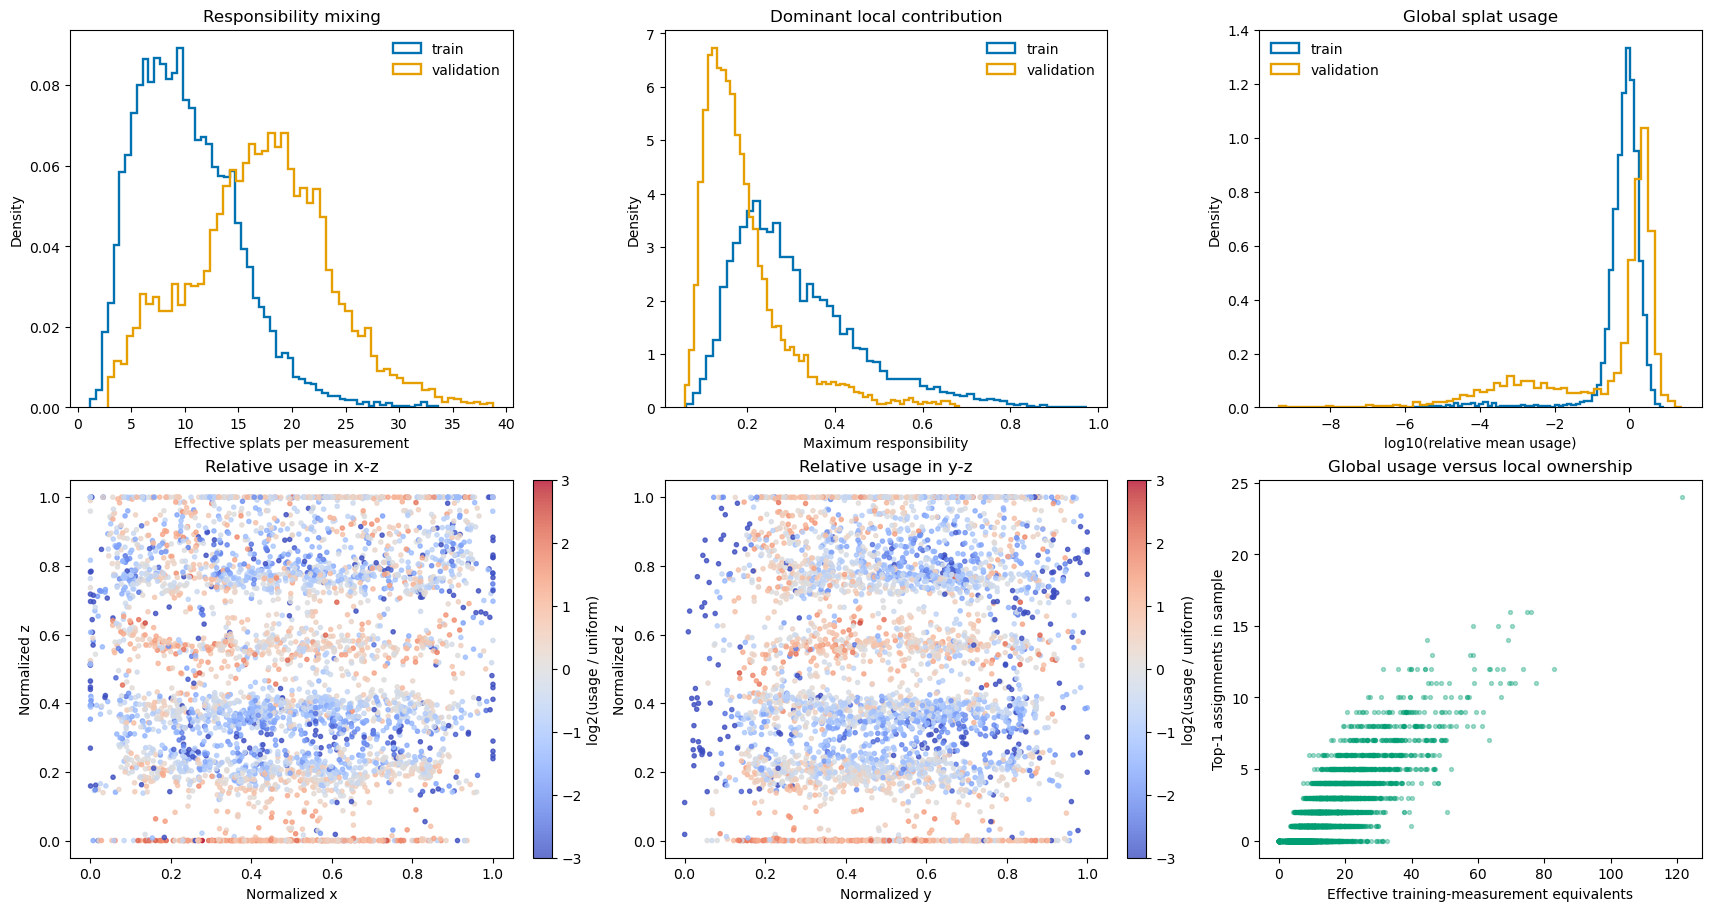

In [19]:
responsibility_sample_size = 8192
responsibility_seed = volumetric_seed + 20

def sample_split_indices(indices, sample_size, seed):
    if len(indices) <= sample_size:
        return indices
    generator = torch.Generator(device=indices.device if indices.is_cuda else 'cpu')
    generator.manual_seed(seed)
    positions = torch.randperm(len(indices), generator=generator, device=indices.device)[:sample_size]
    return indices[positions]

def responsibility_diagnostics(model, indices, *, split_name, sample_size, seed):
    sampled_indices = sample_split_indices(indices, sample_size, seed)
    model.eval()
    with torch.no_grad():
        weights = model.compute_weights(volumetric_coordinates[sampled_indices])
        mean_usage = weights.mean(dim=0)
        peak_usage = weights.max(dim=0).values
        selected_count = (weights > 0).sum(dim=0)
        selected_weight_sum = weights.sum(dim=0)
        mean_when_selected = selected_weight_sum / selected_count.clamp_min(1)
        top1_indices = weights.argmax(dim=1)
        top1_count = torch.bincount(top1_indices, minlength=model.num_splats)
        entropy = -(weights * weights.clamp_min(1e-12).log()).sum(dim=1)
        effective_splats = entropy.exp()
        maximum_responsibility = weights.max(dim=1).values

    num_splats = model.num_splats
    split_measurement_count = len(indices)
    relative_mean_usage = num_splats * mean_usage
    effective_measurement_equivalents = split_measurement_count * mean_usage
    splat_table = pd.DataFrame({
        'splat_index': np.arange(num_splats),
        'mean_responsibility': mean_usage.cpu().numpy(),
        'relative_mean_usage': relative_mean_usage.cpu().numpy(),
        'effective_measurement_equivalents': effective_measurement_equivalents.cpu().numpy(),
        'sample_selected_fraction': (selected_count.float() / len(sampled_indices)).cpu().numpy(),
        'mean_responsibility_when_selected': mean_when_selected.cpu().numpy(),
        'peak_responsibility': peak_usage.cpu().numpy(),
        'sample_top1_assignments': top1_count.cpu().numpy(),
    })
    summary = {
        'split': split_name,
        'measurements_in_split': split_measurement_count,
        'measurements_sampled': len(sampled_indices),
        'uniform_mean_responsibility': 1.0 / num_splats,
        'mean_effective_splats_per_measurement': effective_splats.mean().item(),
        'median_effective_splats_per_measurement': effective_splats.median().item(),
        'mean_maximum_responsibility': maximum_responsibility.mean().item(),
        'median_maximum_responsibility': maximum_responsibility.median().item(),
        'splats_with_top1_assignment': int((top1_count > 0).sum().item()),
        'splats_above_uniform_mean_usage': int((relative_mean_usage > 1.0).sum().item()),
    }
    details = {
        'effective_splats': effective_splats.cpu().numpy(),
        'maximum_responsibility': maximum_responsibility.cpu().numpy(),
    }
    return summary, splat_table, details

responsibility_results = {}
for split_offset, split_name in enumerate(['train', 'validation']):
    responsibility_results[split_name] = responsibility_diagnostics(
        volumetric_splat_model,
        volumetric_split_indices[split_name],
        split_name=split_name,
        sample_size=responsibility_sample_size,
        seed=responsibility_seed + split_offset,
    )
responsibility_summary = pd.DataFrame([
    result[0] for result in responsibility_results.values()
])
display(responsibility_summary.map(format_scalar))

fig, axes = plt.subplots(2, 3, figsize=(17, 9), constrained_layout=True)
for split_name, color in [('train', '#0072b2'), ('validation', '#e69f00')]:
    _, splat_table, details = responsibility_results[split_name]
    axes[0, 0].hist(
        details['effective_splats'], bins=60, density=True, histtype='step',
        linewidth=1.7, color=color, label=split_name,
    )
    axes[0, 1].hist(
        details['maximum_responsibility'], bins=60, density=True, histtype='step',
        linewidth=1.7, color=color, label=split_name,
    )
    positive_relative_usage = splat_table.loc[
        splat_table['relative_mean_usage'] > 0, 'relative_mean_usage'
    ]
    axes[0, 2].hist(
        np.log10(positive_relative_usage), bins=60, density=True, histtype='step',
        linewidth=1.7, color=color, label=split_name,
    )
for ax in axes[0]:
    ax.legend(frameon=False)
axes[0, 0].set_title('Responsibility mixing')
axes[0, 0].set_xlabel('Effective splats per measurement')
axes[0, 0].set_ylabel('Density')
axes[0, 1].set_title('Dominant local contribution')
axes[0, 1].set_xlabel('Maximum responsibility')
axes[0, 1].set_ylabel('Density')
axes[0, 2].set_title('Global splat usage')
axes[0, 2].set_xlabel('log10(relative mean usage)')
axes[0, 2].set_ylabel('Density')

training_usage_table = responsibility_results['train'][1]
usage_color = np.log2(training_usage_table['relative_mean_usage'].clip(lower=1e-3))
for ax, horizontal_axis, title in [
    (axes[1, 0], 0, 'Relative usage in x-z'),
    (axes[1, 1], 1, 'Relative usage in y-z'),
]:
    points = ax.scatter(
        learned_means[:, horizontal_axis], learned_means[:, 2],
        c=usage_color, s=9, alpha=0.78, cmap='coolwarm', vmin=-3, vmax=3,
    )
    ax.set_title(title)
    ax.set_xlabel('Normalized x' if horizontal_axis == 0 else 'Normalized y')
    ax.set_ylabel('Normalized z')
    fig.colorbar(points, ax=ax, fraction=0.046, pad=0.04, label='log2(usage / uniform)')
axes[1, 2].scatter(
    training_usage_table['effective_measurement_equivalents'],
    training_usage_table['sample_top1_assignments'],
    s=8, alpha=0.35, color='#009e73',
)
axes[1, 2].set_title('Global usage versus local ownership')
axes[1, 2].set_xlabel('Effective training-measurement equivalents')
axes[1, 2].set_ylabel('Top-1 assignments in sample')
save_figure(fig, 'volumetric_responsibility_diagnostics')
plt.show()

## Post-hoc bandwidth sensitivity

This diagnostic changes learned x-y and z scales only during validation evaluation and restores the trained parameters afterward. It tests whether the current field would interpolate better with broader or narrower support without confounding bandwidth with another optimization run.

The sweep uses a fixed validation subset and never accesses test expression. Because kernel sharpness and scale are mathematically confounded, separate x-y and z scale multipliers are more interpretable than changing sharpness first.

,xy_scale_multiplier,z_scale_multiplier,mae,composition_cosine,log_total_mae,n,mean_effective_splats,median_effective_splats,mean_maximum_responsibility
0,0.75,0.75,0.4654,0.6955,0.3508,5000,8.946,8.602,0.33110
1,0.75,1.00,0.4634,0.6996,0.3481,5000,10.090,9.807,0.29070
2,0.75,1.25,0.4625,0.7014,0.3467,5000,10.850,10.510,0.27080
3,0.75,1.50,0.4621,0.7026,0.3455,5000,11.640,11.180,0.25690
4,0.75,2.00,0.4619,0.7046,0.3432,5000,13.380,12.930,0.23360
5,1.00,0.75,0.4653,0.7018,0.3443,5000,14.910,14.850,0.22960
6,1.00,1.00,0.4630,0.7062,0.3415,5000,17.110,17.450,0.19190
7,1.00,1.25,0.4621,0.7081,0.3401,5000,18.410,18.730,0.17410
8,1.00,1.50,0.4616,0.7091,0.3391,5000,19.700,19.970,0.16300
9,1.00,2.00,0.4615,0.7104,0.3377,5000,22.440,22.620,0.14630


Validation-best post-hoc bandwidths


,objective,xy_scale_multiplier,z_scale_multiplier,mae,composition_cosine,log_total_mae,n,mean_effective_splats,median_effective_splats,mean_maximum_responsibility
0,composition cosine,1.25,2.0,0.4627,0.7120,0.3356,5000.0,32.02,33.15,0.09945
1,per-gene MAE,1.00,2.0,0.4615,0.7104,0.3377,5000.0,22.44,22.62,0.14630
2,log-total MAE,1.50,2.0,0.4644,0.7115,0.3350,5000.0,40.25,41.97,0.07271


Frozen validation-selected bandwidth
{'xy_scale_multiplier': 1.0, 'z_scale_multiplier': 1.5, 'validation_metrics': {'mae': 0.4619, 'composition_cosine': 0.7085, 'log_total_mae': 0.3423, 'n': 20000}}


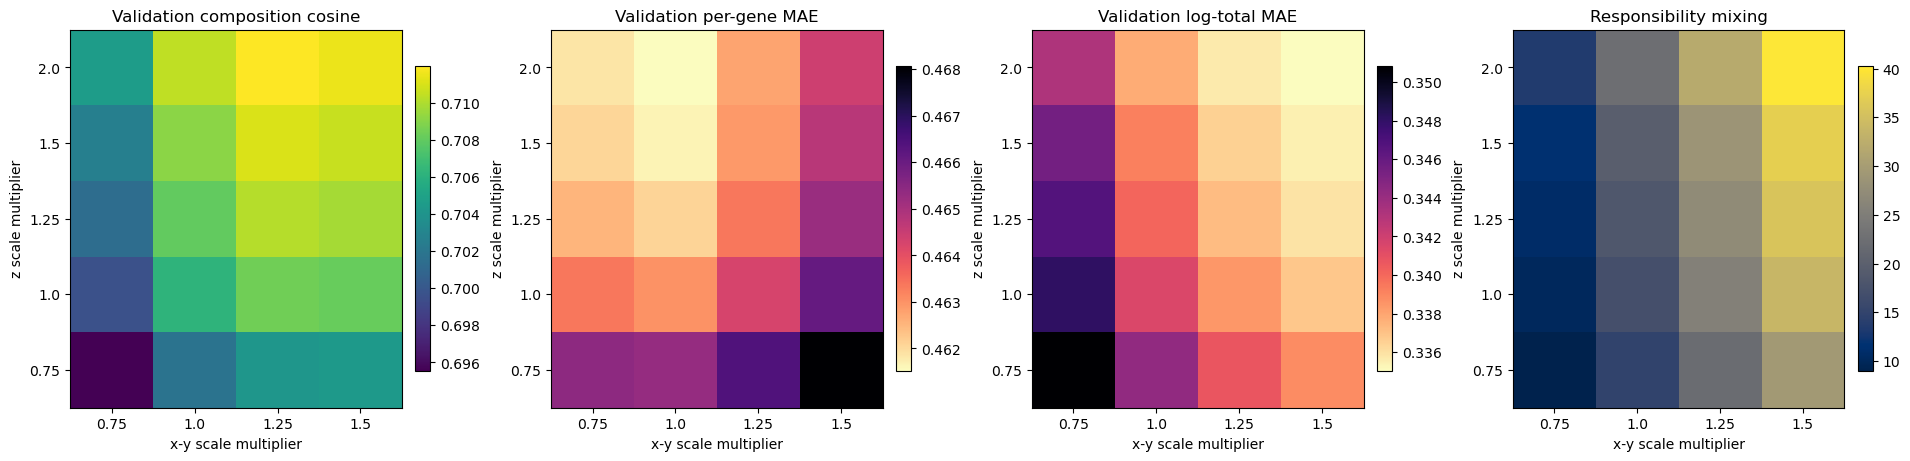

In [20]:
bandwidth_xy_multipliers = [0.75, 1.0, 1.25, 1.5]
bandwidth_z_multipliers = [0.75, 1.0, 1.25, 1.5, 2.0]
frozen_xy_scale_multiplier = 1.0
frozen_z_scale_multiplier = 1.5
bandwidth_sweep_validation_size = 5000
bandwidth_mixing_sample_size = 2048
bandwidth_validation_indices = sample_split_indices(
    volumetric_split_indices['validation'],
    bandwidth_sweep_validation_size,
    volumetric_seed + 30,
)
bandwidth_mixing_indices = sample_split_indices(
    bandwidth_validation_indices,
    bandwidth_mixing_sample_size,
    volumetric_seed + 31,
)

def summarize_query_mixing(model, indices):
    model.eval()
    with torch.no_grad():
        weights = model.compute_weights(volumetric_coordinates[indices])
        entropy = -(weights * weights.clamp_min(1e-12).log()).sum(dim=1)
        effective_splats = entropy.exp()
        maximum_responsibility = weights.max(dim=1).values
    return {
        'mean_effective_splats': effective_splats.mean().item(),
        'median_effective_splats': effective_splats.median().item(),
        'mean_maximum_responsibility': maximum_responsibility.mean().item(),
    }

trained_log_scales = validation_selected_log_scales.clone()
bandwidth_rows = []
try:
    for xy_multiplier in bandwidth_xy_multipliers:
        for z_multiplier in bandwidth_z_multipliers:
            with torch.no_grad():
                volumetric_splat_model.log_scales.copy_(trained_log_scales)
                volumetric_splat_model.log_scales[:, :2].add_(float(np.log(xy_multiplier)))
                volumetric_splat_model.log_scales[:, 2].add_(float(np.log(z_multiplier)))
            metrics = evaluate_volumetric_field(
                volumetric_splat_model, bandwidth_validation_indices
            )
            mixing = summarize_query_mixing(
                volumetric_splat_model, bandwidth_mixing_indices
            )
            bandwidth_rows.append({
                'xy_scale_multiplier': xy_multiplier,
                'z_scale_multiplier': z_multiplier,
                **metrics,
                **mixing,
            })
finally:
    with torch.no_grad():
        volumetric_splat_model.log_scales.copy_(trained_log_scales)
        volumetric_splat_model.log_scales[:, :2].add_(
            float(np.log(frozen_xy_scale_multiplier))
        )
        volumetric_splat_model.log_scales[:, 2].add_(
            float(np.log(frozen_z_scale_multiplier))
        )
bandwidth_sweep = pd.DataFrame(bandwidth_rows)
display(bandwidth_sweep.map(format_scalar))

bandwidth_objective_best = pd.DataFrame([
    {'objective': 'composition cosine', **bandwidth_sweep.loc[
        bandwidth_sweep['composition_cosine'].idxmax()
    ].to_dict()},
    {'objective': 'per-gene MAE', **bandwidth_sweep.loc[
        bandwidth_sweep['mae'].idxmin()
    ].to_dict()},
    {'objective': 'log-total MAE', **bandwidth_sweep.loc[
        bandwidth_sweep['log_total_mae'].idxmin()
    ].to_dict()},
])
print('Validation-best post-hoc bandwidths')
display(bandwidth_objective_best.map(format_scalar))
frozen_bandwidth_validation_metrics = evaluate_volumetric_field(
    volumetric_splat_model, volumetric_split_indices['validation']
)
print('Frozen validation-selected bandwidth')
print(format_for_display({
    'xy_scale_multiplier': frozen_xy_scale_multiplier,
    'z_scale_multiplier': frozen_z_scale_multiplier,
    'validation_metrics': frozen_bandwidth_validation_metrics,
}))

fig, axes = plt.subplots(1, 4, figsize=(19, 4.5), constrained_layout=True)
for ax, value_column, title, cmap in [
    (axes[0], 'composition_cosine', 'Validation composition cosine', 'viridis'),
    (axes[1], 'mae', 'Validation per-gene MAE', 'magma_r'),
    (axes[2], 'log_total_mae', 'Validation log-total MAE', 'magma_r'),
    (axes[3], 'mean_effective_splats', 'Responsibility mixing', 'cividis'),
]:
    pivot = bandwidth_sweep.pivot(
        index='z_scale_multiplier', columns='xy_scale_multiplier', values=value_column
    )
    image = ax.imshow(pivot.to_numpy(), origin='lower', aspect='auto', cmap=cmap)
    ax.set_xticks(np.arange(len(pivot.columns)), labels=[str(value) for value in pivot.columns])
    ax.set_yticks(np.arange(len(pivot.index)), labels=[str(value) for value in pivot.index])
    ax.set_xlabel('x-y scale multiplier')
    ax.set_ylabel('z scale multiplier')
    ax.set_title(title)
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
save_figure(fig, 'volumetric_bandwidth_sensitivity')
plt.show()

## Three-section reconstruction view

This single 3D scene illustrates the reconstruction mechanism rather than the cross-validation design. Observed expression on the two flanking sections anchors the lower and upper planes. The central plane contains nested markers at identical coordinates: the larger outer marker is the released reference expression and the smaller inner marker is the splat reconstruction. Matching colors indicate agreement; a differently colored outer halo indicates local error.

All splat centers near the three-section interval are shown faintly. To keep the figure readable, wireframes are restricted to splats with the greatest integrated responsibility on the central section and whose one-scale z support intersects it. Each wireframe is a visualization contour, not a hard kernel boundary. The displayed gene is selected by training-set variance unless `reconstruction_3d_gene` is set explicitly.

/tmp/ipykernel_1024447/674710092.py:321: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.draw()


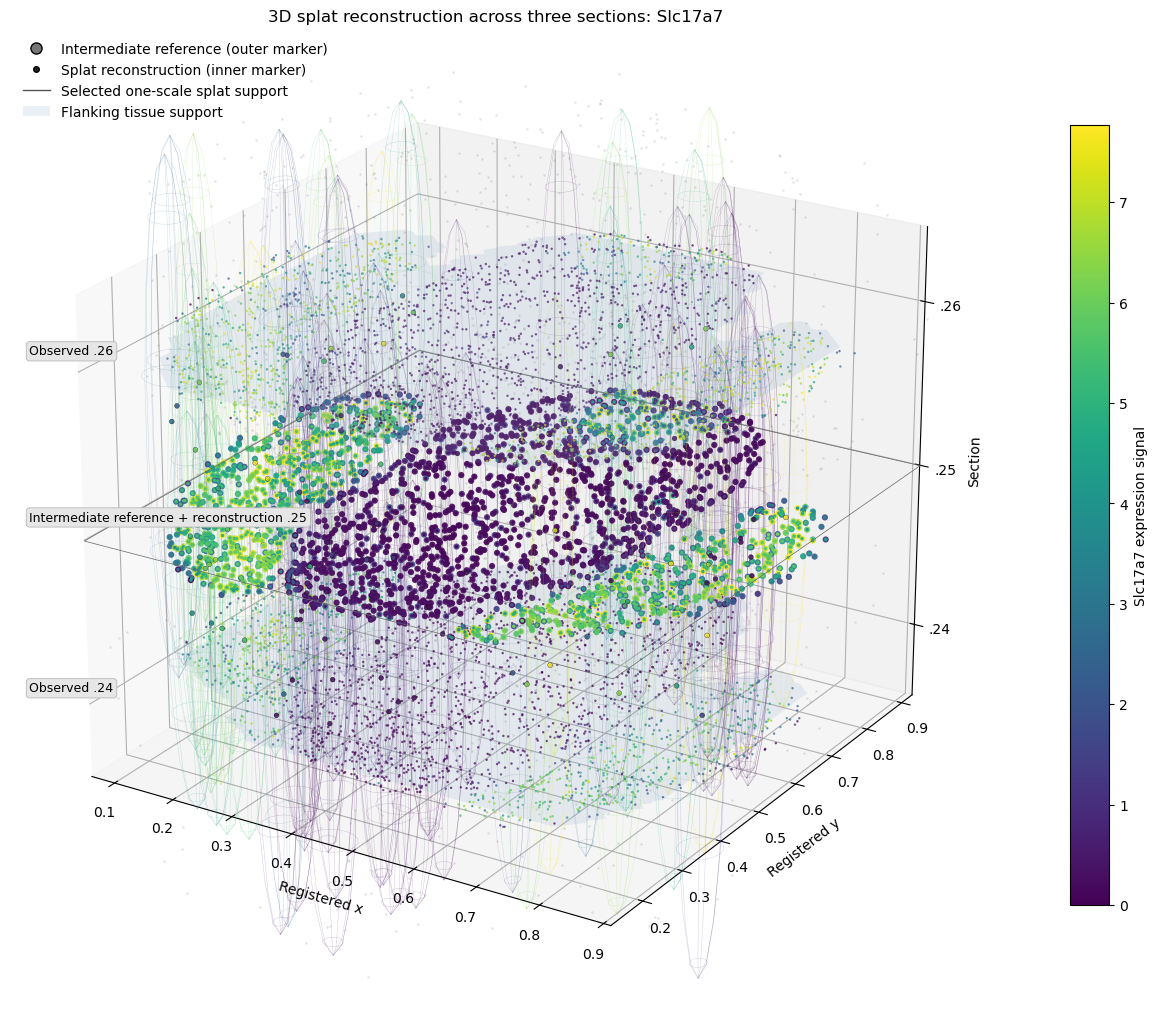

{'gene': 'Slc17a7', 'displayed_splats': 100, 'displayed_responsibility_mass': 0.1469, 'central_reference_measurements_displayed': 2500, 'flanking_tissue_mask_fraction': {'C57BL6J-638850.24': 0.7427, 'C57BL6J-638850.26': 0.7853}, 'central_gene_mae': 1.051, 'central_gene_correlation': 0.857}


In [21]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from mpl_toolkits.mplot3d import proj3d
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from scipy import ndimage

reconstruction_3d_gene = None
reconstruction_3d_max_splats = 100
reconstruction_3d_points_per_section = 2500
reconstruction_3d_support_radius = 1.0
reconstruction_3d_responsibility_batch_size = 1024
reconstruction_3d_mask_grid_size = 96
reconstruction_3d_mask_alpha = 0.16

central_section_position = pilot_section_labels.index(validation_section_label)
reconstruction_section_labels = [
    pilot_section_labels[central_section_position - 1],
    validation_section_label,
    pilot_section_labels[central_section_position + 1],
]
cohort_section_array_3d = cohort_metadata['brain_section_label'].to_numpy()
section_indices_3d = {
    section_label: torch.from_numpy(np.flatnonzero(
        cohort_section_array_3d == section_label
    )).long().to(device)
    for section_label in reconstruction_section_labels
}
central_indices_3d = section_indices_3d[validation_section_label]
section_z_3d = {
    section_label: float(
        volumetric_coordinates[indices, 2].mean().item()
    )
    for section_label, indices in section_indices_3d.items()
}
central_z_3d = section_z_3d[validation_section_label]

if reconstruction_3d_gene is None:
    with torch.no_grad():
        training_gene_variance_3d = volumetric_targets[
            train_indices_device
        ].float().var(dim=0)
    reconstruction_3d_gene_index = int(
        training_gene_variance_3d.argmax().item()
    )
    reconstruction_3d_gene = str(
        gene_symbols.iloc[reconstruction_3d_gene_index]
    )
else:
    matching_gene_indices = np.flatnonzero(
        gene_symbols.to_numpy(dtype=str) == str(reconstruction_3d_gene)
    )
    if not len(matching_gene_indices):
        raise ValueError(f'Unknown reconstruction_3d_gene: {reconstruction_3d_gene}')
    reconstruction_3d_gene_index = int(matching_gene_indices[0])

volumetric_splat_model.eval()
central_responsibility_sum = torch.zeros(
    volumetric_num_splats, device=device
)
with torch.no_grad():
    for start in range(0, len(central_indices_3d), reconstruction_3d_responsibility_batch_size):
        batch_indices = central_indices_3d[
            start:start + reconstruction_3d_responsibility_batch_size
        ]
        central_responsibility_sum += volumetric_splat_model.compute_weights(
            volumetric_coordinates[batch_indices]
        ).sum(dim=0)
    splat_means_3d = volumetric_splat_model.means.detach().clone()
    splat_scales_3d = volumetric_splat_model.log_scales.detach().exp().clone()
    splat_rotations_3d = volumetric_splat_model.rotation.detach().clone().squeeze(-1)
    splat_gene_rates_3d = volumetric_splat_model.splat_rates()[
        :, reconstruction_3d_gene_index
    ].detach().clone()
central_mean_responsibility = central_responsibility_sum / len(central_indices_3d)
support_intersects_central = (
    (splat_means_3d[:, 2] - central_z_3d).abs()
    <= reconstruction_3d_support_radius * splat_scales_3d[:, 2]
)
candidate_splat_indices_3d = torch.nonzero(
    support_intersects_central, as_tuple=False
).reshape(-1)
if not len(candidate_splat_indices_3d):
    raise RuntimeError('No learned splat support intersects the central section.')
num_display_splats_3d = min(
    reconstruction_3d_max_splats, len(candidate_splat_indices_3d)
)
candidate_responsibility_3d = central_mean_responsibility[
    candidate_splat_indices_3d
]
selected_candidate_positions_3d = torch.topk(
    candidate_responsibility_3d, k=num_display_splats_3d
).indices
selected_splat_indices_3d = candidate_splat_indices_3d[
    selected_candidate_positions_3d
]
selected_responsibility_mass_3d = central_mean_responsibility[
    selected_splat_indices_3d
].sum().item()

plot_rng_3d = np.random.default_rng(volumetric_seed + 60)
plot_indices_3d = {}
for section_label, indices in section_indices_3d.items():
    indices_cpu = indices.detach().cpu().numpy()
    if len(indices_cpu) > reconstruction_3d_points_per_section:
        indices_cpu = plot_rng_3d.choice(
            indices_cpu, size=reconstruction_3d_points_per_section, replace=False
        )
    plot_indices_3d[section_label] = torch.from_numpy(
        np.asarray(indices_cpu)
    ).long().to(device)

section_coordinates_3d = {}
section_observed_gene_3d = {}
with torch.no_grad():
    for section_label, indices in plot_indices_3d.items():
        section_coordinates_3d[section_label] = volumetric_coordinates[
            indices
        ].detach().cpu().numpy()
        section_observed_gene_3d[section_label] = volumetric_targets[
            indices, reconstruction_3d_gene_index
        ].detach().cpu().numpy()
    central_plot_indices_3d = plot_indices_3d[validation_section_label]
    central_predicted_gene_3d = volumetric_splat_model.mixed_rates(
        volumetric_coordinates[central_plot_indices_3d]
    )[:, reconstruction_3d_gene_index].detach().cpu().numpy()
central_reference_gene_3d = section_observed_gene_3d[validation_section_label]

signal_values_3d = np.concatenate([
    section_observed_gene_3d[reconstruction_section_labels[0]],
    central_reference_gene_3d,
    central_predicted_gene_3d,
    section_observed_gene_3d[reconstruction_section_labels[2]],
])
signal_vmax_3d = max(float(np.quantile(signal_values_3d, 0.99)), 1e-8)
signal_normalization_3d = plt.Normalize(vmin=0.0, vmax=signal_vmax_3d)
signal_cmap_3d = plt.get_cmap('viridis')

all_plot_coordinates_3d = np.concatenate(list(section_coordinates_3d.values()))
x_min_3d, y_min_3d = np.quantile(all_plot_coordinates_3d[:, :2], 0.01, axis=0)
x_max_3d, y_max_3d = np.quantile(all_plot_coordinates_3d[:, :2], 0.99, axis=0)
lower_z_3d = section_z_3d[reconstruction_section_labels[0]]
upper_z_3d = section_z_3d[reconstruction_section_labels[2]]

fig = plt.figure(figsize=(13, 10), constrained_layout=True)
ax = fig.add_subplot(111, projection='3d')
central_plane_vertices_3d = [[
    (x_min_3d, y_min_3d, central_z_3d),
    (x_max_3d, y_min_3d, central_z_3d),
    (x_max_3d, y_max_3d, central_z_3d),
    (x_min_3d, y_max_3d, central_z_3d),
]]
ax.add_collection3d(Poly3DCollection(
    central_plane_vertices_3d, facecolor='#bdbdbd', edgecolor='#666666',
    linewidth=0.5, alpha=0.025,
))

def tissue_support_mask_3d(section_label):
    section_xy = volumetric_coordinates[
        section_indices_3d[section_label], :2
    ].detach().cpu().numpy()
    occupancy, x_edges, y_edges = np.histogram2d(
        section_xy[:, 0], section_xy[:, 1],
        bins=reconstruction_3d_mask_grid_size,
        range=[[x_min_3d, x_max_3d], [y_min_3d, y_max_3d]],
    )
    mask = occupancy > 0
    mask = ndimage.binary_dilation(mask, iterations=1)
    mask = ndimage.binary_closing(mask, iterations=2)
    mask = ndimage.binary_fill_holes(mask)
    component_labels, component_count = ndimage.label(mask)
    if component_count:
        component_sizes = np.bincount(component_labels.ravel())
        minimum_component_size = max(12, int(0.0025 * mask.size))
        retained_components = np.flatnonzero(
            component_sizes >= minimum_component_size
        )
        retained_components = retained_components[retained_components != 0]
        mask = np.isin(component_labels, retained_components)
    x_centers = 0.5 * (x_edges[:-1] + x_edges[1:])
    y_centers = 0.5 * (y_edges[:-1] + y_edges[1:])
    mask_x, mask_y = np.meshgrid(x_centers, y_centers, indexing='ij')
    return mask_x, mask_y, mask

tissue_mask_fraction_3d = {}
for section_label in [
    reconstruction_section_labels[0], reconstruction_section_labels[2]
]:
    mask_x, mask_y, mask = tissue_support_mask_3d(section_label)
    tissue_mask_fraction_3d[section_label] = float(mask.mean())
    ax.contourf(
        mask_x, mask_y, mask.astype(float), zdir='z',
        offset=section_z_3d[section_label], levels=[0.5, 1.5],
        colors=['#80a6c8'], alpha=reconstruction_3d_mask_alpha,
        antialiased=True,
    )

nearby_center_mask_3d = (
    (splat_means_3d[:, 2] >= lower_z_3d - normalized_section_spacing)
    & (splat_means_3d[:, 2] <= upper_z_3d + normalized_section_spacing)
)
nearby_centers_3d = splat_means_3d[nearby_center_mask_3d].cpu().numpy()
ax.scatter(
    nearby_centers_3d[:, 0], nearby_centers_3d[:, 1], nearby_centers_3d[:, 2],
    s=1.2, color='#555555', alpha=0.09, depthshade=False, rasterized=True,
)

ellipsoid_u_3d = np.linspace(0.0, 2.0 * np.pi, 18)
ellipsoid_v_3d = np.linspace(0.0, np.pi, 10)
ellipsoid_u_3d, ellipsoid_v_3d = np.meshgrid(
    ellipsoid_u_3d, ellipsoid_v_3d
)
selected_splat_indices_cpu_3d = selected_splat_indices_3d.detach().cpu().tolist()
for splat_index in selected_splat_indices_cpu_3d:
    center = splat_means_3d[splat_index].cpu().numpy()
    scale = (
        reconstruction_3d_support_radius
        * splat_scales_3d[splat_index].cpu().numpy()
    )
    rotation = float(splat_rotations_3d[splat_index].item())
    local_x = scale[0] * np.sin(ellipsoid_v_3d) * np.cos(ellipsoid_u_3d)
    local_y = scale[1] * np.sin(ellipsoid_v_3d) * np.sin(ellipsoid_u_3d)
    global_x = center[0] + np.cos(rotation) * local_x - np.sin(rotation) * local_y
    global_y = center[1] + np.sin(rotation) * local_x + np.cos(rotation) * local_y
    global_z = center[2] + scale[2] * np.cos(ellipsoid_v_3d)
    splat_color = signal_cmap_3d(signal_normalization_3d(
        float(splat_gene_rates_3d[splat_index].item())
    ))
    ax.plot_wireframe(
        global_x, global_y, global_z, rstride=2, cstride=3,
        color=splat_color, linewidth=0.35, alpha=0.22,
    )

for section_label in [reconstruction_section_labels[0], reconstruction_section_labels[2]]:
    coordinates = section_coordinates_3d[section_label]
    values = section_observed_gene_3d[section_label]
    ax.scatter(
        coordinates[:, 0], coordinates[:, 1], coordinates[:, 2],
        c=values, cmap=signal_cmap_3d, norm=signal_normalization_3d,
        s=3, alpha=0.72, linewidths=0, depthshade=False, rasterized=True,
    )

central_coordinates_3d = section_coordinates_3d[validation_section_label]
ax.scatter(
    central_coordinates_3d[:, 0], central_coordinates_3d[:, 1],
    central_coordinates_3d[:, 2], c=central_reference_gene_3d,
    cmap=signal_cmap_3d, norm=signal_normalization_3d, s=20, alpha=0.9,
    linewidths=0, depthshade=False, rasterized=True,
)
ax.scatter(
    central_coordinates_3d[:, 0], central_coordinates_3d[:, 1],
    central_coordinates_3d[:, 2], c=central_predicted_gene_3d,
    cmap=signal_cmap_3d, norm=signal_normalization_3d, s=6, alpha=1.0,
    linewidths=0, depthshade=False, rasterized=True,
)

section_suffixes_3d = [
    section_label.rsplit('.', 1)[-1]
    for section_label in reconstruction_section_labels
]
section_annotation_specs_3d = []
for section_label, suffix in zip(reconstruction_section_labels, section_suffixes_3d):
    role = 'Intermediate reference + reconstruction' if section_label == validation_section_label else 'Observed'
    coordinates = section_coordinates_3d[section_label]
    section_annotation_specs_3d.append({
        'position': (
            float(np.median(coordinates[:, 0])),
            float(np.median(coordinates[:, 1])),
            section_z_3d[section_label],
        ),
        'text': f'{role} .{suffix}',
    })

selected_centers_3d = splat_means_3d[selected_splat_indices_3d].cpu().numpy()
selected_gene_rates_3d = splat_gene_rates_3d[
    selected_splat_indices_3d
].cpu().numpy()
ax.scatter(
    selected_centers_3d[:, 0], selected_centers_3d[:, 1],
    selected_centers_3d[:, 2], c=selected_gene_rates_3d,
    cmap=signal_cmap_3d, norm=signal_normalization_3d, s=12,
    edgecolors='black', linewidths=0.25, alpha=0.9, depthshade=False,
)

ax.set_xlim(x_min_3d, x_max_3d)
ax.set_ylim(y_min_3d, y_max_3d)
ax.set_zlim(
    lower_z_3d - 0.45 * normalized_section_spacing,
    upper_z_3d + 0.45 * normalized_section_spacing,
)
ax.set_box_aspect((1.0, 1.0, 0.85))
ax.view_init(elev=23, azim=-58)
ax.set_xlabel('Registered x')
ax.set_ylabel('Registered y')
ax.set_zticks(
    [section_z_3d[label] for label in reconstruction_section_labels],
    labels=[f'.{suffix}' for suffix in section_suffixes_3d],
)
ax.set_zlabel('Section')
ax.set_title(
    f'3D splat reconstruction across three sections: {reconstruction_3d_gene}'
)
legend_handles_3d = [
    Line2D([0], [0], marker='o', color='none', markerfacecolor='#777777',
           markersize=8, label='Intermediate reference (outer marker)'),
    Line2D([0], [0], marker='o', color='none', markerfacecolor='#222222',
           markersize=4, label='Splat reconstruction (inner marker)'),
    Line2D([0], [0], color='#555555', linewidth=1.0,
           label='Selected one-scale splat support'),
    Patch(facecolor='#80a6c8', alpha=reconstruction_3d_mask_alpha,
          label='Flanking tissue support'),
]
ax.legend(handles=legend_handles_3d, loc='upper left', frameon=False)
colorbar_mappable_3d = plt.cm.ScalarMappable(
    norm=signal_normalization_3d, cmap=signal_cmap_3d
)
colorbar_mappable_3d.set_array([])
fig.colorbar(
    colorbar_mappable_3d, ax=ax, fraction=0.035, pad=0.08,
    label=f'{reconstruction_3d_gene} expression signal',
)
fig.canvas.draw()
for annotation_spec in section_annotation_specs_3d:
    projected_x, projected_y, _ = proj3d.proj_transform(
        *annotation_spec['position'], ax.get_proj()
    )
    display_position = ax.transData.transform((projected_x, projected_y))
    axes_position = ax.transAxes.inverted().transform(display_position)
    ax.text2D(
        0.02, axes_position[1], annotation_spec['text'],
        transform=ax.transAxes, fontsize=9, color='black',
        horizontalalignment='left', verticalalignment='center',
        zorder=1000, clip_on=False,
        bbox={
            'facecolor': '#e6e6e6', 'edgecolor': '#b8b8b8',
            'boxstyle': 'round,pad=0.25', 'linewidth': 0.6, 'alpha': 1.0,
        },
    )
save_figure(fig, 'volumetric_three_section_splat_reconstruction')
plt.show()

central_gene_correlation_3d = np.corrcoef(
    central_reference_gene_3d, central_predicted_gene_3d
)[0, 1]
print(format_for_display({
    'gene': reconstruction_3d_gene,
    'displayed_splats': num_display_splats_3d,
    'displayed_responsibility_mass': selected_responsibility_mass_3d,
    'central_reference_measurements_displayed': len(central_reference_gene_3d),
    'flanking_tissue_mask_fraction': tissue_mask_fraction_3d,
    'central_gene_mae': float(np.mean(np.abs(
        central_predicted_gene_3d - central_reference_gene_3d
    ))),
    'central_gene_correlation': central_gene_correlation_3d,
}))


## Validation baselines

The field with its validation-selected checkpoint and frozen `(x-y, z) = (1.0, 1.5)` bandwidth multipliers is compared on validation section `.25` against interpolation from its two adjacent observed sections, 3D KNN, an MAE-only coordinate MLP, and a coordinate MLP trained with the same biological objective as the splat field. KNN hyperparameters are selected on the same fixed validation subset used for diagnostic selection, then selected configurations are evaluated on the complete validation section.

These are validation results, not final performance estimates. Test section `.29` remains sealed. Per-measurement metrics are accompanied by normalized x-y grid aggregation because an expression field cannot predict stochastic single-cell identity from coordinates alone.

In [22]:
baseline_tuning_indices = bandwidth_validation_indices
baseline_full_validation_indices = volumetric_split_indices['validation']
baseline_neighbor_batch_size = 512
baseline_knn_values = [16, 32, 64]
baseline_mlp_hidden_dim = 256
baseline_mlp_epochs = 200
baseline_mlp_batch_size = 4096
baseline_mlp_learning_rate = 1e-3
baseline_mlp_validation_every = 10
baseline_bio_composition_weight = volumetric_composition_weight
baseline_bio_total_signal_weight = volumetric_total_signal_weight
baseline_bio_mae_weight = volumetric_mae_weight
baseline_bio_mae_refine_fraction = volumetric_mae_refine_fraction
baseline_spatial_grid_sizes = [32, 64]
baseline_minimum_measurements_per_bin = 5

def prediction_metrics(predicted_signal, target_signal):
    predicted_signal = predicted_signal.float()
    target_signal = target_signal.to(predicted_signal.device).float()
    composition_cosine = torch.nn.functional.cosine_similarity(
        predicted_signal, target_signal, dim=1, eps=1e-8
    ).mean()
    return {
        'mae': (predicted_signal - target_signal).abs().mean().item(),
        'composition_cosine': composition_cosine.item(),
        'log_total_mae': (
            torch.log1p(predicted_signal.sum(dim=1))
            - torch.log1p(target_signal.sum(dim=1))
        ).abs().mean().item(),
        'n': len(target_signal),
    }

def predict_field_signal(model, indices, batch_size=volumetric_evaluation_batch_size):
    predictions = []
    model.eval()
    with torch.no_grad():
        for start in range(0, len(indices), batch_size):
            batch_indices = indices[start:start + batch_size]
            predictions.append(model.mixed_rates(volumetric_coordinates[batch_indices]).cpu())
    return torch.cat(predictions, dim=0)

def nearest_xy_prediction(query_indices, reference_indices):
    reference_xy = volumetric_coordinates[reference_indices, :2]
    reference_targets = volumetric_targets[reference_indices]
    predictions = []
    with torch.no_grad():
        for start in range(0, len(query_indices), baseline_neighbor_batch_size):
            batch_indices = query_indices[start:start + baseline_neighbor_batch_size]
            distances = torch.cdist(volumetric_coordinates[batch_indices, :2], reference_xy)
            nearest = distances.argmin(dim=1)
            predictions.append(reference_targets[nearest].cpu())
    return torch.cat(predictions, dim=0)

cohort_section_array = cohort_metadata['brain_section_label'].to_numpy()
lower_section_label = pilot_section_labels[pilot_section_labels.index(validation_section_label) - 1]
upper_section_label = pilot_section_labels[pilot_section_labels.index(validation_section_label) + 1]
lower_reference_indices = torch.from_numpy(np.flatnonzero(
    cohort_section_array == lower_section_label
)).long().to(device)
upper_reference_indices = torch.from_numpy(np.flatnonzero(
    cohort_section_array == upper_section_label
)).long().to(device)
lower_prediction = nearest_xy_prediction(
    baseline_full_validation_indices, lower_reference_indices
)
upper_prediction = nearest_xy_prediction(
    baseline_full_validation_indices, upper_reference_indices
)
validation_z = float(cohort_metadata.iloc[baseline_full_validation_indices[0].item()]['z'])
lower_z = float(cohort_metadata.iloc[lower_reference_indices[0].item()]['z'])
upper_z = float(cohort_metadata.iloc[upper_reference_indices[0].item()]['z'])
upper_fraction = (validation_z - lower_z) / (upper_z - lower_z)
adjacent_interpolation_prediction = (
    (1.0 - upper_fraction) * lower_prediction + upper_fraction * upper_prediction
)

def knn_predictions(query_indices, k_values):
    k_values = sorted(set(int(value) for value in k_values))
    maximum_k = max(k_values)
    reference_coordinates = volumetric_coordinates[train_indices_device]
    reference_targets = volumetric_targets[train_indices_device]
    prediction_batches = {k: [] for k in k_values}
    with torch.no_grad():
        for start in range(0, len(query_indices), baseline_neighbor_batch_size):
            batch_indices = query_indices[start:start + baseline_neighbor_batch_size]
            distances = torch.cdist(
                volumetric_coordinates[batch_indices], reference_coordinates
            )
            neighbor_indices = torch.topk(
                distances, k=maximum_k, largest=False, sorted=True, dim=1
            ).indices
            neighbor_targets = reference_targets[neighbor_indices]
            for k in k_values:
                prediction_batches[k].append(neighbor_targets[:, :k].mean(dim=1).cpu())
    return {k: torch.cat(batches, dim=0) for k, batches in prediction_batches.items()}

knn_tuning_predictions = knn_predictions(baseline_tuning_indices, baseline_knn_values)
knn_tuning_rows = []
knn_tuning_targets = volumetric_targets[baseline_tuning_indices].cpu()
for k, prediction in knn_tuning_predictions.items():
    knn_tuning_rows.append({'k': k, **prediction_metrics(prediction, knn_tuning_targets)})
knn_tuning_summary = pd.DataFrame(knn_tuning_rows)
display(knn_tuning_summary.map(format_scalar))

def objective_selected_settings(summary, parameter_columns):
    selected = []
    for objective, column, direction in [
        ('composition cosine', 'composition_cosine', 'max'),
        ('per-gene MAE', 'mae', 'min'),
        ('log-total MAE', 'log_total_mae', 'min'),
    ]:
        row_index = summary[column].idxmax() if direction == 'max' else summary[column].idxmin()
        row = summary.loc[row_index]
        selected.append({
            'objective': objective,
            **{parameter: row[parameter] for parameter in parameter_columns},
        })
    return pd.DataFrame(selected).drop_duplicates(parameter_columns).reset_index(drop=True)

selected_knn_settings = objective_selected_settings(knn_tuning_summary, ['k'])
print('Selected KNN settings')
display(selected_knn_settings.map(format_scalar))

,k,mae,composition_cosine,log_total_mae,n
0,16,0.4688,0.6936,0.3449,5000
1,32,0.4676,0.7030,0.3410,5000
2,64,0.4680,0.7070,0.3380,5000


Selected KNN settings


,objective,k
0,composition cosine,64.0
1,per-gene MAE,32.0


### Coordinate MLPs and complete-validation comparison

`MLP (MAE only)` is trained with section-balanced batches and selected by validation MAE. `MLP (Bio Objective)` follows the splat curriculum: composition and log-total losses throughout training, followed by an MAE refinement phase, and the same constrained validation checkpoint rule. Selected KNN configurations are then rerun on all validation measurements. Only validation predictions are retained for model selection and the spatially aggregated comparison.

MLP (MAE only) epoch 1/200 {'mae': 0.5394, 'composition_cosine': 0.5866, 'log_total_mae': 0.3689, 'n': 5000}
MLP (MAE only) epoch 20/200 {'mae': 0.4169, 'composition_cosine': 0.553, 'log_total_mae': 0.9816, 'n': 5000}
MLP (MAE only) epoch 40/200 {'mae': 0.4151, 'composition_cosine': 0.5616, 'log_total_mae': 0.9605, 'n': 5000}
MLP (MAE only) epoch 60/200 {'mae': 0.4133, 'composition_cosine': 0.5621, 'log_total_mae': 0.9693, 'n': 5000}
MLP (MAE only) epoch 80/200 {'mae': 0.412, 'composition_cosine': 0.5651, 'log_total_mae': 0.9789, 'n': 5000}
MLP (MAE only) epoch 100/200 {'mae': 0.4109, 'composition_cosine': 0.5645, 'log_total_mae': 0.9658, 'n': 5000}
MLP (MAE only) epoch 120/200 {'mae': 0.4102, 'composition_cosine': 0.5637, 'log_total_mae': 0.9735, 'n': 5000}
MLP (MAE only) epoch 140/200 {'mae': 0.4096, 'composition_cosine': 0.5646, 'log_total_mae': 0.9649, 'n': 5000}
MLP (MAE only) epoch 160/200 {'mae': 0.4091, 'composition_cosine': 0.5669, 'log_total_mae': 0.9567, 'n': 5000}
MLP (MAE 

,model,mae,composition_cosine,log_total_mae,n
4,MLP (MAE only),0.4078,0.5682,0.9359,20000
0,AE-neighbor splat,0.4619,0.7085,0.3423,20000
2,3D KNN (k=32),0.4673,0.7028,0.3435,20000
3,3D KNN (k=64),0.4677,0.7069,0.3410,20000
5,MLP (Bio Objective),0.4678,0.7016,0.3374,20000
1,Adjacent-section interpolation,0.4953,0.5961,0.3904,20000


,model,grid_size,mae,composition_cosine,log_total_mae,n,eligible_bins
0,AE-neighbor splat,32,0.1635,0.9407,0.1555,636,636
1,AE-neighbor splat,64,0.2261,0.9025,0.1882,2083,2083
2,Adjacent-section interpolation,32,0.1853,0.9216,0.1518,636,636
3,Adjacent-section interpolation,64,0.2729,0.8515,0.2068,2083,2083
4,3D KNN (k=32),32,0.1627,0.9406,0.1376,636,636
5,3D KNN (k=32),64,0.2279,0.9011,0.1745,2083,2083
6,3D KNN (k=64),32,0.1596,0.9418,0.1312,636,636
7,3D KNN (k=64),64,0.2239,0.9046,0.1691,2083,2083
8,MLP (MAE only),32,0.3261,0.7406,0.9962,636,636
9,MLP (MAE only),64,0.3425,0.7140,1.0010,2083,2083


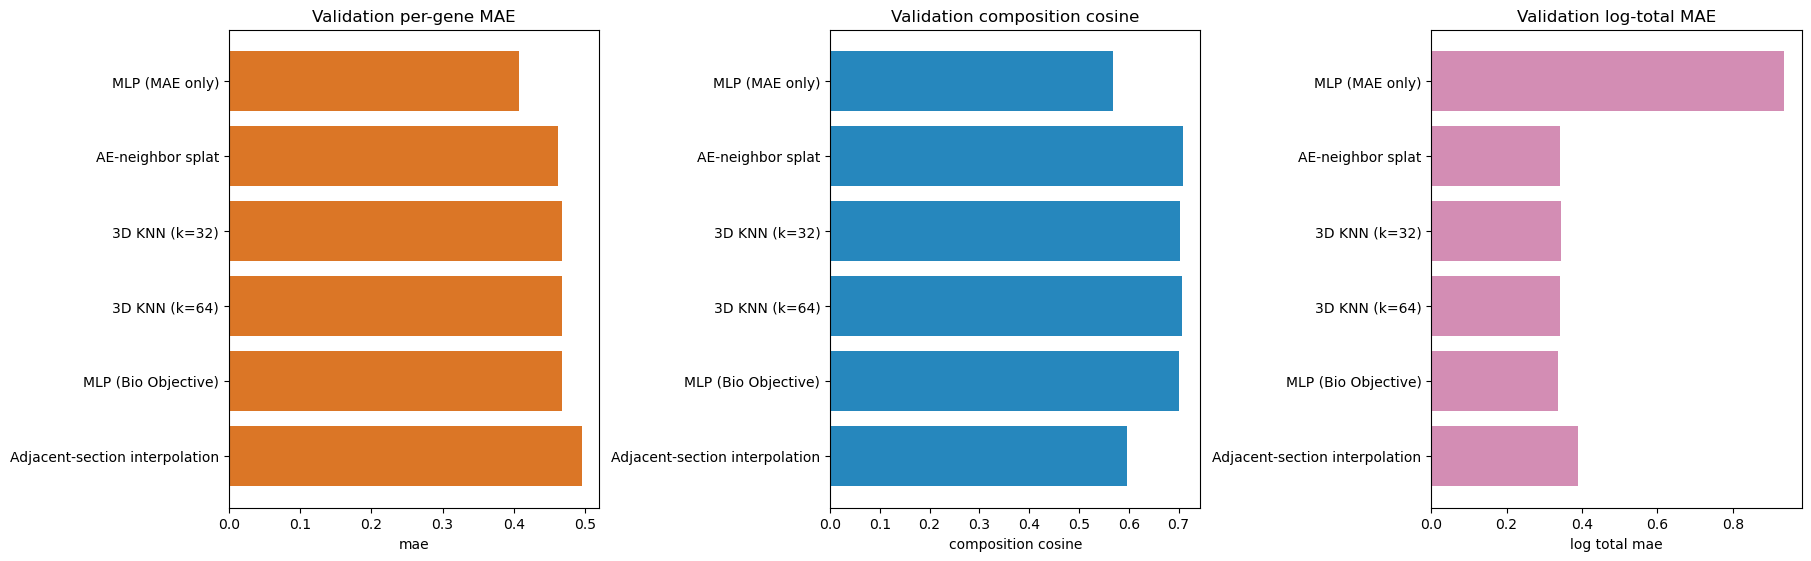

In [23]:
set_seed(volumetric_seed + 40)
baseline_mlp = CountMLP(
    input_dim=3, hidden_dim=baseline_mlp_hidden_dim, output_dim=volumetric_targets.shape[1]
).to(device)
baseline_mlp_optimizer = torch.optim.Adam(
    baseline_mlp.parameters(), lr=baseline_mlp_learning_rate
)
baseline_mlp_history = {'epoch': [], 'validation_mae': []}
best_mlp_validation_mae = float('inf')
best_mlp_epoch = None
best_mlp_state = None
for epoch in range(baseline_mlp_epochs):
    baseline_mlp.train()
    for batch_indices in make_section_balanced_batches(
        training_indices_by_section, baseline_mlp_batch_size
    ):
        predicted_log_signal = baseline_mlp(volumetric_coordinates[batch_indices])
        loss = mae_count_loss(predicted_log_signal, volumetric_targets[batch_indices])
        baseline_mlp_optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(baseline_mlp.parameters(), max_norm=5.0)
        baseline_mlp_optimizer.step()
    evaluate_mlp = (
        epoch == 0
        or (epoch + 1) % baseline_mlp_validation_every == 0
        or epoch == baseline_mlp_epochs - 1
    )
    if evaluate_mlp:
        baseline_mlp.eval()
        with torch.no_grad():
            tuning_prediction = torch.exp(
                baseline_mlp(volumetric_coordinates[baseline_tuning_indices])
            ).cpu()
        metrics = prediction_metrics(tuning_prediction, knn_tuning_targets)
        baseline_mlp_history['epoch'].append(epoch + 1)
        baseline_mlp_history['validation_mae'].append(metrics['mae'])
        if metrics['mae'] < best_mlp_validation_mae:
            best_mlp_validation_mae = metrics['mae']
            best_mlp_epoch = epoch + 1
            best_mlp_state = {
                key: value.detach().cpu().clone()
                for key, value in baseline_mlp.state_dict().items()
            }
        if epoch == 0 or (epoch + 1) % 20 == 0 or epoch == baseline_mlp_epochs - 1:
            print(
                f'MLP (MAE only) epoch {epoch + 1}/{baseline_mlp_epochs}',
                format_for_display(metrics),
            )
if best_mlp_state is None:
    raise RuntimeError('MLP (MAE only) did not produce a validation checkpoint.')
baseline_mlp.load_state_dict(best_mlp_state)
baseline_mlp.to(device).eval()

set_seed(volumetric_seed + 41)
baseline_bio_mlp = CountMLP(
    input_dim=3, hidden_dim=baseline_mlp_hidden_dim,
    output_dim=volumetric_targets.shape[1],
).to(device)
baseline_bio_optimizer = torch.optim.Adam(
    baseline_bio_mlp.parameters(), lr=baseline_mlp_learning_rate
)
baseline_bio_refine_start_epoch = int(round(
    (1.0 - baseline_bio_mae_refine_fraction) * baseline_mlp_epochs
))
baseline_bio_checkpoints = []
for epoch in range(baseline_mlp_epochs):
    baseline_bio_mlp.train()
    mae_refine_active = epoch >= baseline_bio_refine_start_epoch
    for batch_indices in make_section_balanced_batches(
        training_indices_by_section, baseline_mlp_batch_size
    ):
        targets = volumetric_targets[batch_indices]
        predicted_log_signal = baseline_bio_mlp(
            volumetric_coordinates[batch_indices]
        )
        predicted_signal = torch.exp(predicted_log_signal)
        composition_loss = composition_cosine_loss(predicted_signal, targets)
        total_signal_loss = log_total_count_loss(predicted_log_signal, targets)
        mae_loss = (
            mae_count_loss(predicted_log_signal, targets)
            if mae_refine_active
            else predicted_log_signal.new_tensor(0.0)
        )
        loss = (
            baseline_bio_composition_weight * composition_loss
            + baseline_bio_total_signal_weight * total_signal_loss
            + baseline_bio_mae_weight * mae_loss
        )
        baseline_bio_optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(baseline_bio_mlp.parameters(), max_norm=5.0)
        baseline_bio_optimizer.step()
    evaluate_mlp = (
        epoch == 0
        or (epoch + 1) % baseline_mlp_validation_every == 0
        or epoch == baseline_bio_refine_start_epoch
        or epoch == baseline_mlp_epochs - 1
    )
    if evaluate_mlp:
        baseline_bio_mlp.eval()
        with torch.no_grad():
            tuning_prediction = torch.exp(
                baseline_bio_mlp(volumetric_coordinates[baseline_tuning_indices])
            ).cpu()
        metrics = prediction_metrics(tuning_prediction, knn_tuning_targets)
        baseline_bio_checkpoints.append({
            'epoch': epoch + 1,
            'metrics': metrics.copy(),
            'state_dict': {
                key: value.detach().cpu().clone()
                for key, value in baseline_bio_mlp.state_dict().items()
            },
        })
        if epoch == 0 or (epoch + 1) % 20 == 0 or epoch == baseline_mlp_epochs - 1:
            print(
                f'MLP (Bio Objective) epoch {epoch + 1}/{baseline_mlp_epochs}',
                'mae_refine' if mae_refine_active else 'composition',
                format_for_display(metrics),
            )
if not baseline_bio_checkpoints:
    raise RuntimeError('MLP (Bio Objective) did not produce a validation checkpoint.')
best_bio_validation_cosine = max(
    checkpoint['metrics']['composition_cosine']
    for checkpoint in baseline_bio_checkpoints
)
best_bio_validation_log_total_mae = min(
    checkpoint['metrics']['log_total_mae']
    for checkpoint in baseline_bio_checkpoints
)
eligible_bio_checkpoints = [
    checkpoint for checkpoint in baseline_bio_checkpoints
    if checkpoint['metrics']['composition_cosine']
    >= best_bio_validation_cosine - volumetric_checkpoint_cosine_tolerance
    and checkpoint['metrics']['log_total_mae']
    <= best_bio_validation_log_total_mae + volumetric_checkpoint_log_total_tolerance
]
if not eligible_bio_checkpoints:
    raise RuntimeError(
        'No biological-objective MLP checkpoint satisfies the validation tolerances.'
    )
selected_bio_checkpoint = min(
    eligible_bio_checkpoints,
    key=lambda checkpoint: (
        checkpoint['metrics']['mae'],
        -checkpoint['metrics']['composition_cosine'],
        checkpoint['metrics']['log_total_mae'],
        checkpoint['epoch'],
    ),
)
best_bio_mlp_epoch = selected_bio_checkpoint['epoch']
baseline_bio_mlp.load_state_dict(selected_bio_checkpoint['state_dict'])
baseline_bio_mlp.to(device).eval()
for checkpoint in baseline_bio_checkpoints:
    checkpoint.pop('state_dict')

def predict_mlp_signal(
    model, indices, batch_size=volumetric_evaluation_batch_size
):
    prediction_batches = []
    model.eval()
    with torch.no_grad():
        for start in range(0, len(indices), batch_size):
            batch_indices = indices[start:start + batch_size]
            prediction_batches.append(torch.exp(
                model(volumetric_coordinates[batch_indices])
            ).cpu())
    return torch.cat(prediction_batches, dim=0)

full_validation_targets = volumetric_targets[baseline_full_validation_indices].cpu()
selected_validation_predictions = {
    'AE-neighbor splat': predict_field_signal(
        volumetric_splat_model, baseline_full_validation_indices
    ),
    'Adjacent-section interpolation': adjacent_interpolation_prediction,
}
selected_knn_values = sorted(set(selected_knn_settings['k'].astype(int).tolist()))
full_knn_predictions = knn_predictions(
    baseline_full_validation_indices, selected_knn_values
)
for k, prediction in full_knn_predictions.items():
    selected_validation_predictions[f'3D KNN (k={k})'] = prediction
selected_validation_predictions['MLP (MAE only)'] = predict_mlp_signal(
    baseline_mlp, baseline_full_validation_indices
)
selected_validation_predictions['MLP (Bio Objective)'] = predict_mlp_signal(
    baseline_bio_mlp, baseline_full_validation_indices
)

baseline_validation_rows = []
for model_name, prediction in selected_validation_predictions.items():
    baseline_validation_rows.append({
        'model': model_name,
        **prediction_metrics(prediction, full_validation_targets),
    })
baseline_validation_summary = pd.DataFrame(baseline_validation_rows).sort_values('mae')
print(format_for_display({
    'mae_only_mlp_selected_epoch': best_mlp_epoch,
    'bio_objective_mlp_selected_epoch': best_bio_mlp_epoch,
    'bio_objective_mlp_eligible_checkpoints': len(eligible_bio_checkpoints),
}))
display(baseline_validation_summary.map(format_scalar))

def aggregate_validation_grid(prediction, grid_size):
    validation_coordinates_cpu = cohort_coordinate_tensor[
        baseline_full_validation_indices.detach().cpu()
    ].cpu()
    xy_index = torch.clamp(
        torch.floor(validation_coordinates_cpu[:, :2] * grid_size).long(),
        min=0, max=grid_size - 1,
    )
    flat_index = xy_index[:, 1] * grid_size + xy_index[:, 0]
    unique_bins, inverse, counts = torch.unique(
        flat_index, return_inverse=True, return_counts=True
    )
    target_sum = torch.zeros((len(unique_bins), full_validation_targets.shape[1]))
    prediction_sum = torch.zeros_like(target_sum)
    target_sum.index_add_(0, inverse, full_validation_targets)
    prediction_sum.index_add_(0, inverse, prediction)
    eligible = counts >= baseline_minimum_measurements_per_bin
    target_mean = target_sum[eligible] / counts[eligible, None]
    prediction_mean = prediction_sum[eligible] / counts[eligible, None]
    return prediction_metrics(prediction_mean, target_mean) | {
        'eligible_bins': int(eligible.sum().item())
    }

spatial_validation_rows = []
for model_name, prediction in selected_validation_predictions.items():
    for grid_size in baseline_spatial_grid_sizes:
        spatial_validation_rows.append({
            'model': model_name,
            'grid_size': grid_size,
            **aggregate_validation_grid(prediction, grid_size),
        })
spatial_validation_summary = pd.DataFrame(spatial_validation_rows)
display(spatial_validation_summary.map(format_scalar))

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), constrained_layout=True)
plot_summary = baseline_validation_summary.iloc[::-1]
for ax, metric, title, color in [
    (axes[0], 'mae', 'Validation per-gene MAE', '#d55e00'),
    (axes[1], 'composition_cosine', 'Validation composition cosine', '#0072b2'),
    (axes[2], 'log_total_mae', 'Validation log-total MAE', '#cc79a7'),
]:
    ax.barh(plot_summary['model'], plot_summary[metric], color=color, alpha=0.85)
    ax.set_title(title)
    ax.set_xlabel(metric.replace('_', ' '))
save_figure(fig, 'volumetric_validation_baselines')
plt.show()

## Final sealed-test evaluation

This section is run only after the splat checkpoint, bandwidth multiplier, KNN settings, and MLP checkpoints have been frozen using validation section `.25`. It evaluates test section `.29` once. Test expression is used only for the reported metrics and qualitative maps below, never for model selection.

The representation table separates prediction quality from compactness. Timings are end-to-end measurements on the current machine for a fixed test-coordinate subset and should be treated as implementation-specific rather than hardware-independent complexity estimates.

Final frozen test performance


,model,mae,composition_cosine,log_total_mae,n
4,MLP (MAE only),0.4142,0.5974,0.8110,20000
2,3D KNN (k=32),0.4769,0.7206,0.3351,20000
3,3D KNN (k=64),0.4774,0.7250,0.3367,20000
0,AE-neighbor splat,0.4782,0.7239,0.3354,20000
5,MLP (Bio Objective),0.4806,0.7201,0.3357,20000
1,Adjacent-section interpolation,0.5112,0.6238,0.3811,20000


Final frozen test performance after x-y aggregation


,model,grid_size,mae,composition_cosine,log_total_mae,n,eligible_bins
0,AE-neighbor splat,32,0.1955,0.9207,0.1462,691,691
1,AE-neighbor splat,64,0.2517,0.8901,0.1734,1984,1984
2,Adjacent-section interpolation,32,0.2179,0.9033,0.1558,691,691
3,Adjacent-section interpolation,64,0.2995,0.8439,0.2038,1984,1984
4,3D KNN (k=32),32,0.1974,0.9174,0.1421,691,691
5,3D KNN (k=32),64,0.2533,0.8877,0.1699,1984,1984
6,3D KNN (k=64),32,0.1951,0.9192,0.1425,691,691
7,3D KNN (k=64),64,0.2496,0.8917,0.1706,1984,1984
8,MLP (MAE only),32,0.3279,0.7507,0.8438,691,691
9,MLP (MAE only),64,0.3470,0.7293,0.8487,1984,1984


{'benchmark_measurements': 2048, 'device': 'cuda', 'splat_to_training_measurement_ratio': 0.06827}


,model,representation_units,unit_type,storage_mib,inference_ms_for_benchmark,measurements_per_second
0,AE-neighbor splat,4096,splats,0.9909,2.3050,888700.0
1,Adjacent-section interpolation,20000,reference measurements,42.1100,3.2840,623600.0
2,3D KNN (k=64),60000,reference measurements,126.6000,4.6090,444400.0
3,MLP (MAE only),208166,parameters,0.7941,0.6341,3230000.0
4,MLP (Bio Objective),208166,parameters,0.7941,0.9116,2247000.0


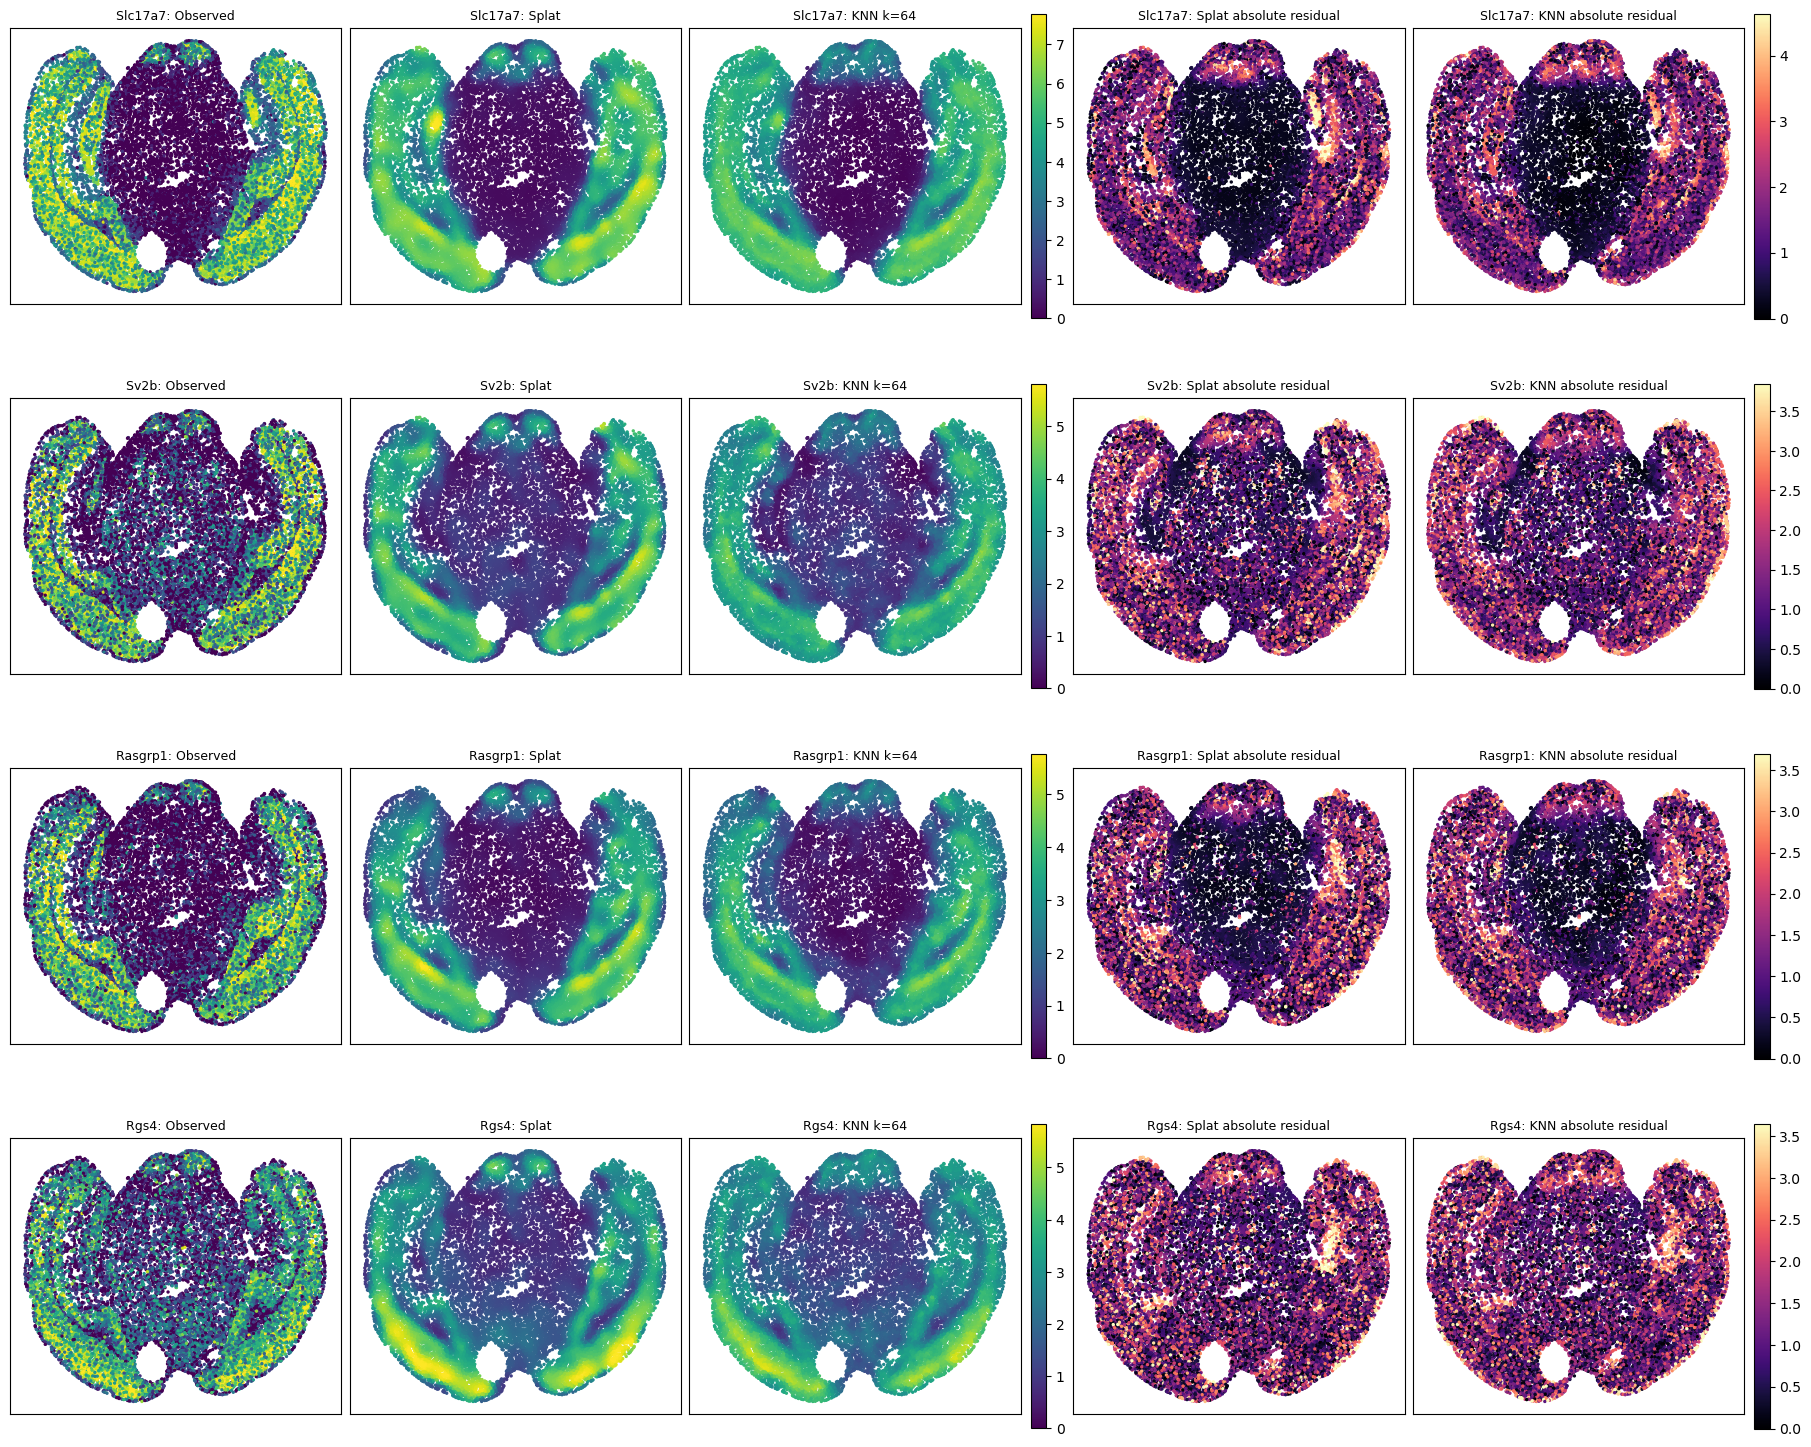

Held-out genes selected by training-set expression variance


,gene,splat_mae,knn_mae,splat_correlation,knn_correlation
0,Slc17a7,1.317,1.334,0.7999,0.8137
1,Sv2b,1.227,1.265,0.6569,0.6567
2,Rasgrp1,1.084,1.111,0.7209,0.7178
3,Rgs4,1.183,1.187,0.6201,0.6184


In [24]:
import time

baseline_full_test_indices = volumetric_split_indices['test']
full_test_targets = volumetric_targets[baseline_full_test_indices].cpu()

def adjacent_section_prediction(query_indices, heldout_section_label):
    section_position = pilot_section_labels.index(heldout_section_label)
    lower_label = pilot_section_labels[section_position - 1]
    upper_label = pilot_section_labels[section_position + 1]
    if role_by_section[lower_label] != 'train' or role_by_section[upper_label] != 'train':
        raise RuntimeError('Adjacent interpolation requires training planes on both sides.')
    lower_indices = torch.from_numpy(np.flatnonzero(
        cohort_section_array == lower_label
    )).long().to(device)
    upper_indices = torch.from_numpy(np.flatnonzero(
        cohort_section_array == upper_label
    )).long().to(device)
    lower_values = nearest_xy_prediction(query_indices, lower_indices)
    upper_values = nearest_xy_prediction(query_indices, upper_indices)
    query_z = float(cohort_metadata.iloc[query_indices[0].item()]['z'])
    lower_z = float(cohort_metadata.iloc[lower_indices[0].item()]['z'])
    upper_z = float(cohort_metadata.iloc[upper_indices[0].item()]['z'])
    upper_fraction = (query_z - lower_z) / (upper_z - lower_z)
    return (1.0 - upper_fraction) * lower_values + upper_fraction * upper_values

selected_test_predictions = {
    'AE-neighbor splat': predict_field_signal(
        volumetric_splat_model, baseline_full_test_indices
    ),
    'Adjacent-section interpolation': adjacent_section_prediction(
        baseline_full_test_indices, test_section_label
    ),
}
full_test_knn_predictions = knn_predictions(
    baseline_full_test_indices, selected_knn_values
)
for k, prediction in full_test_knn_predictions.items():
    selected_test_predictions[f'3D KNN (k={k})'] = prediction
selected_test_predictions['MLP (MAE only)'] = predict_mlp_signal(
    baseline_mlp, baseline_full_test_indices
)
selected_test_predictions['MLP (Bio Objective)'] = predict_mlp_signal(
    baseline_bio_mlp, baseline_full_test_indices
)

test_rows = []
for model_name, prediction in selected_test_predictions.items():
    test_rows.append({
        'model': model_name,
        **prediction_metrics(prediction, full_test_targets),
    })
final_test_summary = pd.DataFrame(test_rows).sort_values('mae')
print('Final frozen test performance')
display(final_test_summary.map(format_scalar))

def aggregate_spatial_grid(prediction, targets, indices, grid_size):
    coordinates_cpu = cohort_coordinate_tensor[indices.detach().cpu()].cpu()
    xy_index = torch.clamp(
        torch.floor(coordinates_cpu[:, :2] * grid_size).long(),
        min=0, max=grid_size - 1,
    )
    flat_index = xy_index[:, 1] * grid_size + xy_index[:, 0]
    unique_bins, inverse, counts = torch.unique(
        flat_index, return_inverse=True, return_counts=True
    )
    target_sum = torch.zeros((len(unique_bins), targets.shape[1]))
    prediction_sum = torch.zeros_like(target_sum)
    target_sum.index_add_(0, inverse, targets)
    prediction_sum.index_add_(0, inverse, prediction)
    eligible = counts >= baseline_minimum_measurements_per_bin
    target_mean = target_sum[eligible] / counts[eligible, None]
    prediction_mean = prediction_sum[eligible] / counts[eligible, None]
    return prediction_metrics(prediction_mean, target_mean) | {
        'eligible_bins': int(eligible.sum().item())
    }

spatial_test_rows = []
for model_name, prediction in selected_test_predictions.items():
    for grid_size in baseline_spatial_grid_sizes:
        spatial_test_rows.append({
            'model': model_name,
            'grid_size': grid_size,
            **aggregate_spatial_grid(
                prediction, full_test_targets, baseline_full_test_indices, grid_size
            ),
        })
spatial_test_summary = pd.DataFrame(spatial_test_rows)
print('Final frozen test performance after x-y aggregation')
display(spatial_test_summary.map(format_scalar))

benchmark_knn_k = max(selected_knn_values)
benchmark_size = min(2048, len(baseline_full_test_indices))
benchmark_indices = sample_split_indices(
    baseline_full_test_indices, benchmark_size, volumetric_seed + 50
)

def synchronize_device():
    if device.type == 'cuda':
        torch.cuda.synchronize(device)

def median_inference_seconds(function, repeats=3):
    function()
    synchronize_device()
    runtimes = []
    for _ in range(repeats):
        synchronize_device()
        start = time.perf_counter()
        function()
        synchronize_device()
        runtimes.append(time.perf_counter() - start)
    return float(np.median(runtimes))

benchmark_functions = {
    'AE-neighbor splat': lambda: predict_field_signal(
        volumetric_splat_model, benchmark_indices, batch_size=512
    ),
    'Adjacent-section interpolation': lambda: adjacent_section_prediction(
        benchmark_indices, test_section_label
    ),
    f'3D KNN (k={benchmark_knn_k})': lambda: knn_predictions(
        benchmark_indices, [benchmark_knn_k]
    ),
    'MLP (MAE only)': lambda: predict_mlp_signal(
        baseline_mlp, benchmark_indices, batch_size=512
    ),
    'MLP (Bio Objective)': lambda: predict_mlp_signal(
        baseline_bio_mlp, benchmark_indices, batch_size=512
    ),
}
inference_seconds = {
    model_name: median_inference_seconds(function)
    for model_name, function in benchmark_functions.items()
}

def state_dict_bytes(model):
    return sum(
        tensor.numel() * tensor.element_size()
        for tensor in model.state_dict().values()
    )

knn_storage_bytes = (
    train_coordinates.numel() * train_coordinates.element_size()
    + volumetric_targets[train_indices_device].numel()
    * volumetric_targets.element_size()
)
test_section_position = pilot_section_labels.index(test_section_label)
test_adjacent_labels = [
    pilot_section_labels[test_section_position - 1],
    pilot_section_labels[test_section_position + 1],
]
test_adjacent_indices = torch.from_numpy(np.flatnonzero(
    np.isin(cohort_section_array, test_adjacent_labels)
)).long().to(device)
adjacent_storage_bytes = (
    volumetric_coordinates[test_adjacent_indices, :2].numel()
    * volumetric_coordinates.element_size()
    + volumetric_targets[test_adjacent_indices].numel()
    * volumetric_targets.element_size()
)
representation_rows = [
    {
        'model': 'AE-neighbor splat',
        'representation_units': volumetric_num_splats,
        'unit_type': 'splats',
        'storage_mib': state_dict_bytes(volumetric_splat_model) / 2**20,
    },
    {
        'model': 'Adjacent-section interpolation',
        'representation_units': len(test_adjacent_indices),
        'unit_type': 'reference measurements',
        'storage_mib': adjacent_storage_bytes / 2**20,
    },
    {
        'model': f'3D KNN (k={benchmark_knn_k})',
        'representation_units': len(train_indices_device),
        'unit_type': 'reference measurements',
        'storage_mib': knn_storage_bytes / 2**20,
    },
    {
        'model': 'MLP (MAE only)',
        'representation_units': sum(p.numel() for p in baseline_mlp.parameters()),
        'unit_type': 'parameters',
        'storage_mib': state_dict_bytes(baseline_mlp) / 2**20,
    },
    {
        'model': 'MLP (Bio Objective)',
        'representation_units': sum(p.numel() for p in baseline_bio_mlp.parameters()),
        'unit_type': 'parameters',
        'storage_mib': state_dict_bytes(baseline_bio_mlp) / 2**20,
    },
]
for row in representation_rows:
    runtime = inference_seconds[row['model']]
    row['inference_ms_for_benchmark'] = 1000.0 * runtime
    row['measurements_per_second'] = benchmark_size / runtime
representation_summary = pd.DataFrame(representation_rows)
print(format_for_display({
    'benchmark_measurements': benchmark_size,
    'device': str(device),
    'splat_to_training_measurement_ratio': (
        volumetric_num_splats / len(train_indices_device)
    ),
}))
display(representation_summary.map(format_scalar))

with torch.no_grad():
    training_gene_variance = volumetric_targets[train_indices_device].float().var(dim=0)
qualitative_gene_indices = torch.topk(
    training_gene_variance, k=min(4, volumetric_targets.shape[1])
).indices.cpu()
qualitative_gene_names = [
    str(gene_symbols.iloc[int(index)]) for index in qualitative_gene_indices
]
qualitative_knn_name = f'3D KNN (k={benchmark_knn_k})'
test_xy = cohort_coordinate_tensor[
    baseline_full_test_indices.detach().cpu(), :2
].cpu().numpy()
splat_test_prediction = selected_test_predictions['AE-neighbor splat']
knn_test_prediction = selected_test_predictions[qualitative_knn_name]

test_gene_rows = []
fig, axes = plt.subplots(
    len(qualitative_gene_indices), 5,
    figsize=(18, 3.7 * len(qualitative_gene_indices)),
    constrained_layout=True,
)
for row_index, (gene_index, gene_name) in enumerate(zip(
    qualitative_gene_indices.tolist(), qualitative_gene_names
)):
    observed = full_test_targets[:, gene_index].numpy()
    splat_values = splat_test_prediction[:, gene_index].numpy()
    knn_values = knn_test_prediction[:, gene_index].numpy()
    splat_residual = np.abs(splat_values - observed)
    knn_residual = np.abs(knn_values - observed)
    signal_max = max(
        float(np.quantile(np.concatenate([observed, splat_values, knn_values]), 0.99)),
        1e-8,
    )
    residual_max = max(
        float(np.quantile(np.concatenate([splat_residual, knn_residual]), 0.99)),
        1e-8,
    )
    panels = [
        ('Observed', observed, 'viridis', signal_max),
        ('Splat', splat_values, 'viridis', signal_max),
        (f'KNN k={benchmark_knn_k}', knn_values, 'viridis', signal_max),
        ('Splat absolute residual', splat_residual, 'magma', residual_max),
        ('KNN absolute residual', knn_residual, 'magma', residual_max),
    ]
    for column_index, (title, values, cmap, value_max) in enumerate(panels):
        ax = axes[row_index, column_index]
        scatter = ax.scatter(
            test_xy[:, 0], test_xy[:, 1], c=values, s=2,
            cmap=cmap, vmin=0.0, vmax=value_max, rasterized=True,
        )
        ax.set_aspect('equal')
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_title(f'{gene_name}: {title}', fontsize=9)
        if column_index in {2, 4}:
            fig.colorbar(scatter, ax=ax, fraction=0.046, pad=0.03)
    test_gene_rows.append({
        'gene': gene_name,
        'splat_mae': float(np.mean(splat_residual)),
        'knn_mae': float(np.mean(knn_residual)),
        'splat_correlation': float(np.corrcoef(observed, splat_values)[0, 1]),
        'knn_correlation': float(np.corrcoef(observed, knn_values)[0, 1]),
    })
save_figure(fig, 'volumetric_test_gene_reconstruction')
plt.show()
print('Held-out genes selected by training-set expression variance')
display(pd.DataFrame(test_gene_rows).map(format_scalar))


## Initial implications for the 3D experiment

This inventory establishes several constraints for the next stage:

- the volume contains 59 registered sections from one donor;
- the shared expression panel contains 550 genes;
- approximately 3.94 million cells have both expression rows and registered coordinates;
- section populations and anatomical extents vary strongly with `z`;
- most neighboring sections are separated by the modal `z` interval, but several larger gaps require separate handling;
- the expression matrix should remain backed and be loaded by section during training;
- the initial pilot uses eight sections from registered z=3.6 through z=5.0, all separated by 0.2;
- validation section `.25` and test section `.29` are interior planes with observed training planes immediately above and below them;
- section `.27` remains a flagged damaged training plane and must receive a later include/exclude sensitivity analysis;
- autoencoder training uses equal samples from the six training sections and excludes both held-out sections.

The notebook freezes continuous stratified z initialization, the validation-selected checkpoint, and a 1.5-fold z bandwidth multiplier before the final test section is evaluated. The test comparison includes adjacent-plane interpolation, validation-selected 3D KNN, an explicitly MAE-only MLP, and an MLP trained with the same biological objective as the splat field. It also reports representation size, implementation-specific inference timing, spatially aggregated metrics, and held-out gene maps. The full 19-plane contiguous run from z=1.4 through z=5.0 remains a later expansion after the pilot result is interpreted. Endpoint-cap regularization is intentionally deferred unless the frozen pilot still shows harmful end accumulation.